# CS781 Phase 6 — Abstractive Legal Summarization — Arch 3: Encoder/decoder hybrid (Prefix-LM) (`ARCH = "prefixlm"`)
Adapts **your Phase-1 checkpoint** `P1_REPOS[ARCH]` (`best/`; bart = the v2 retrain) to abstractive summarization of
long legal documents, scored by BERTScore F1 (ROUGE-1 F1 and ROUGE-L F1 secondary).

| | |
|---|---|
| Backbone | Phase-1 prefix-LM `LlamaForCausalLM`: bidirectional attention over the prefix, causal after it |
| Input format | `[document input | SEP_TEXT | summary]` in one sequence of at most 1024 positions; loss on the summary tokens; generation continues after `SEP_TEXT`; the document input + `SEP_TEXT` is the bidirectional prefix (as in Phase-1 pretraining), the summary is causal |
| Long documents (`DOC_SELECT`) | at most `SRC_LEN` document tokens reach the model: `head` (the first `SRC_LEN`), `head_tail` (`HEAD_FRAC` of them from the start, the rest from the end), `even` (pieces of `EVEN_PIECE` tokens evenly spaced over the whole document), `importance` (sentences ranked by TF-IDF cosine similarity to their own document — vectoriser fitted on the training documents, no pretrained model — and the best-ranked ones that fit kept in document order) |
| Training | cross-entropy on the summary tokens only (at most `TGT_LEN`; `<\|endoftext\|>` follows a summary that was not cut) |
| Decoding | `DECODE` (greedy / beam search, length limits, n-gram blocking, repetition penalty); `EXTRA_DECODES` = more decoding settings for the same trained model, each with held-out scores and its own submission zip |
| Methods (`METHOD`) | `full` (reference), `lora`, `qlora` (4-bit NF4 frozen base + LoRA), `lorma` (LoRMA), `adalora` (AdaLoRA), `houlsby` / `pfeiffer` (bottleneck adapters), `prompt` (prompt tuning), `kd` (sequence-level distillation into a smaller student) |
| Validation | no dev split in Phase 6: `HELDOUT_DOCS` training documents are held out (same documents for every run with the same `SEED`); held-out loss and ROUGE during training, ROUGE + BERTScore computed as in `evaluate_phase6.py` at the end |
| Outputs | `submission_<RUN_NAME>.zip` (+ one per `EXTRA_DECODES` entry) + run files in private repo `<hf-user>/cs781-p6` under `runs/<RUN_NAME>/` |

**Before you start**
1. Runtime -> Change runtime type -> **T4 GPU**.
2. Secrets (key icon) -> `HF` = the **same** HF token as Phases 1–5 (reads your `cs781-p1-*` repos and the gated course
   dataset, writes `cs781-p6`).
3. Choose `METHOD`, `DOC_SELECT` in the first code cell, check *Configuration*, then **Run all**.

Another experiment on the same account: change the first cell (the run name follows), **Run all** again — every run
starts from the Phase-1 checkpoint; tokenised documents are cached in the runtime, so a second run skips tokenisation.
`kd` needs a finished teacher run in `cs781-p6` (`TEACHER_RUN`, any architecture, saved with `SAVE_TRAIN_GEN = True`:
the student learns from the summaries the teacher generated for the training documents it was trained on).

Phase-6 rules (capstone §1, §12.2): ≥6 submissions; all four Phase-1 models used and the best four submissions from
different Phase-1 models; ≥4 substantially different experiments, of which ≥3 use different fine-tuning / adaptation
techniques **from the §12.2.1 list** (Houlsby adapters, Pfeiffer adapters, prefix tuning, prompt tuning, LoRA, QLoRA,
AdaLoRA, LoRMA, KD) with **LoRMA compulsory**, and ≥1 is knowledge distillation from a larger or stronger teacher into
a smaller student; runs that differ only in hyperparameters (including decoding settings) do not count. `full` is not
on the §12.2.1 list: it is offered as the full-model reference the §12.5 analysis compares against. Prefix tuning is
not implemented; `prompt` is the soft-prompt technique offered.

In [1]:
ARCH = "prefixlm"                 # fixed for this notebook
METHOD = "lorma"                  # "full" | "lora" | "qlora" | "lorma" | "adalora" | "houlsby" | "pfeiffer" | "prompt" | "kd"
DOC_SELECT = "head"               # "head" | "head_tail" | "even" | "importance"
RUN_NAME = f"{ARCH}_{METHOD}_{DOC_SELECT}"   # unique per experiment (add a suffix when other settings change)

In [2]:
import os, sys, re, json, math, time, random, zipfile, gc, hashlib, itertools, functools, subprocess
from collections import Counter
try:
    import rouge_score, bert_score
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rouge-score", "bert-score"], check=True)
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from huggingface_hub import login, whoami, HfApi, hf_hub_download, snapshot_download
from rouge_score import rouge_scorer, tokenizers as rouge_tokenizers

def get_hf_token():
    try:
        from google.colab import userdata
        return userdata.get("HF")
    except Exception:
        pass
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret("HF")
    except Exception:
        return os.environ["HF_TOKEN"]

HF_TOKEN = get_hf_token()
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)
HF_USER = whoami(token=HF_TOKEN)["name"]
api = HfApi(token=HF_TOKEN)

def hub_push(fn, what, tries=3):
    for t in range(1, tries + 1):
        try:
            fn(); return True
        except Exception as e:
            print(f"  !! {what} upload failed ({t}/{tries}): {e!r}")
            time.sleep(30 * t)
    return False

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
assert DEVICE == "cuda" or os.environ.get("CS781_ALLOW_CPU"), "Switch the runtime to a GPU"
AMP = DEVICE == "cuda"
print(torch.__version__, torch.cuda.get_device_name(0) if AMP else "CPU")
import transformers; print("transformers", transformers.__version__)

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


2.11.0+cu130 Tesla T4
transformers 5.22.0


## Configuration — **all values below are YOUR CHOICE** (document them in the report)
The numbers filled in are placeholders that make the notebook run end to end on a T4, not tuned values. Check the token
statistics printed in the *Tokenizer* section before choosing `SRC_LEN` / `TGT_LEN` / `max_new_tokens`.

In [3]:
DATASET = "Exploration-Lab/CS-781-Capstone"
DATA_DIR = "Phase_6_Summ"                   # folder of this phase in the dataset repo (searched for if the name differs)
# Phase-1 checkpoint (best/) per architecture; bart = the v2 retrain (v1 `cs781-p1-bart` collapsed, never use it)
P1_REPOS = {"llama": f"{HF_USER}/cs781-p1-llama", "bart": f"{HF_USER}/cs781-p1-bart-v2",
            "prefixlm": f"{HF_USER}/cs781-p1-prefixlm", "mistral_swa": f"{HF_USER}/cs781-p1-mistral_swa"}
P6_REPO = f"{HF_USER}/cs781-p6"             # all Phase-6 runs: runs/<RUN_NAME>/...
WORK = "/content/p6" if os.path.isdir("/content") else "/tmp/p6"
RUN_DIR = f"{WORK}/{RUN_NAME}"
CACHE_DIR = f"{WORK}/cache"                 # tokenised documents / summaries, reused by later runs in the same runtime
os.makedirs(RUN_DIR, exist_ok=True); os.makedirs(CACHE_DIR, exist_ok=True)

SEED = 42
HELDOUT_DOCS = 300         # training documents held out for validation (random, seed SEED), never trained on
TRAIN_MAX_DOCS = None      # None = every remaining training document; else a random subset of this many (seeded)

# Document -> model input (all Phase-1 models have 1024 positions)
#   decoder-only: PROMPT_LEN (prompt) + SRC_LEN + tokens of SEP_TEXT + TGT_LEN + 1 <= 1024, and the same with max_new_tokens
#   bart: the encoder reads SRC_LEN (+ 1 <mask>) tokens -- Phase-1 v2 trained the encoder on <= 768 + 1 and the decoder on
#   <= 512 positions; positions above those were never trained
SRC_LEN = 768 if ARCH == "bart" else 512    # document tokens given to the model
TGT_LEN = 512 if ARCH == "bart" else 480    # summary tokens trained on (longer reference summaries are cut)
SEP_TEXT = "\n\nSummary:\n"   # decoder-only: text between the document tokens and the summary
HEAD_FRAC = 0.5            # DOC_SELECT "head_tail": share of SRC_LEN taken from the start of the document
EVEN_PIECE = 128           # DOC_SELECT "even": tokens per piece; SRC_LEN // EVEN_PIECE pieces evenly spaced over the document
TFIDF_MAX_FEATURES = 50000   # DOC_SELECT "importance": vocabulary of the TF-IDF vectoriser (English stop words removed)

# Optimisation
EPOCHS = 3                 # passes over the training documents (MAX_TRAIN_MINUTES may end training first)
MAX_TRAIN_MINUTES = 60     # cap on training time, evaluations excluded; the LR and AdaLoRA schedules follow
                           # max(fraction of steps, fraction of this time), so they complete by the cap
EVAL_EVERY_MINUTES = 15    # held-out evaluation after this many training minutes (and at the end of every epoch)
PATIENCE = 3               # evaluations without improvement of SELECT_METRIC before stopping
BATCH_SIZE = 4             # (document, summary) examples per forward pass
GRAD_ACCUM = 4             # forward passes per optimizer step: effective batch = BATCH_SIZE * GRAD_ACCUM examples
GRAD_CKPT = False          # activation checkpointing (less GPU memory, slower)
LR = {"full": 5e-5, "lora": 5e-4, "qlora": 5e-4, "lorma": 5e-4, "adalora": 5e-4, "houlsby": 5e-4, "pfeiffer": 5e-4, "prompt": 3e-3, "kd": 1e-4}[METHOD]
WEIGHT_DECAY = 0.01
WARMUP_FRAC = 0.06
GRAD_CLIP = 1.0
LABEL_SMOOTHING = 0.0

# Validation during training (held-out documents)
SELECT_METRIC = "loss"     # best checkpoint by: "loss" (held-out loss on the reference summaries) | "rouge1" | "rougeL"
EVAL_LOSS_DOCS = None      # held-out documents for the loss (None = all HELDOUT_DOCS)
EVAL_GEN_DOCS = 48         # held-out documents summarised (greedy, else DECODE) at every evaluation for ROUGE (0 = none)

# Decoding (held-out and test summaries)
DECODE = dict(num_beams=1, max_new_tokens=TGT_LEN, min_new_tokens=0, no_repeat_ngram_size=0, repetition_penalty=1.0, length_penalty=1.0)
EXTRA_DECODES = {}         # name -> changes to DECODE, e.g. {"beam4": {"num_beams": 4}}: the same trained model decodes the
                           # held-out and test documents again; every entry gets its own scores and submission zip
GEN_BATCH = 16             # documents per generation batch (beam search: GEN_BATCH * num_beams sequences)
MAX_SUMMARY_WORDS = None   # post-processing: generated summaries cut to this many words (None = not cut)
EMPTY_FALLBACK_WORDS = 50  # an empty generated summary is replaced by the first words of its document (the evaluator
                           # rejects empty summaries); the number of replacements is reported
BERTSCORE = True           # held-out BERTScore (roberta-large as in evaluate_phase6.py; ~1.4 GB download per runtime)

# Method-specific
ADAPT_TARGETS = ["q_proj", "v_proj"]    # lora / qlora / lorma / adalora: nn.Linear layers that get adapters
                                        # (bart: self- and cross-attention of the encoder and decoder)
RANK, ALPHA = 8, 16                     # lora / qlora / lorma: rank, scale alpha/r
QLORA_BLOCK = 64                        # qlora: weights per NF4 quantisation block (one absmax per block)
QLORA_DOUBLE_QUANT = True               # qlora: absmax constants stored in 8 bits too (double quantisation)
QLORA_MERGE_FOR_INFERENCE = True        # qlora: before generation, dequantise the NF4 weights and add the LoRA update into
                                        # 32-bit nn.Linear weights (same function, faster decoding, more memory)
LORMA_VARIANT = "plus"                  # "plus" = additive-identity rank inflation, "pi" = permutation inflation
ADALORA_INIT_R, ADALORA_TARGET_R = 12, 4  # adalora: initial / final average rank per adapted layer (scale ALPHA/INIT_R)
ADALORA_TINIT, ADALORA_TFINAL = 0.1, 0.2  # adalora: fraction of training before pruning / with the final budget fixed
ADALORA_DELTA_T = 10                    # adalora: optimizer steps between rank reallocations
ADALORA_BETAS = (0.85, 0.85)            # adalora: EMA factors of sensitivity / uncertainty
ADALORA_ORTH = 0.1                      # adalora: weight of the orthogonality regulariser on P and Q
HOULSBY_AT = ["o_proj", "down_proj", "out_proj", "fc2"]   # houlsby: after the attention and FFN output projections
PFEIFFER_AT = ["down_proj", "fc2"]      # pfeiffer: after the FFN output projection only (one adapter per block)
ADAPTER_DIM = 64                        # houlsby / pfeiffer: bottleneck size
ADAPTER_TRAIN_NORMS = True              # houlsby / pfeiffer: layer norms trained too
PROMPT_LEN = 20                         # prompt: learned soft tokens in front of every input

# Knowledge distillation (METHOD == "kd"); the student is this notebook's ARCH with fewer Phase-1 blocks
TEACHER_RUN = "llama_full_head"         # a finished run in P6_REPO that saved train_gen.json
STUDENT_LAYERS = None                   # None = every 2nd block (per stack for bart), or an explicit list
KD_TEACHER_PROB = 1.0                   # per training example: probability that the target is the teacher's summary
                                        # (otherwise the reference summary)

SAVE_TRAIN_GEN = True      # summaries generated (DECODE) for training documents this run trained on, so a later kd run
                           # can use this run as teacher (costs one generation pass over those documents)
TRAIN_GEN_MAX_DOCS = 1000  # None = every document seen in training; else a random subset of them of this size
                           # (a kd student trains on exactly these documents)
SAVE_WEIGHTS = False       # fine-tuned weights to the Hub (not needed for distillation)

METHODS = ("full", "lora", "qlora", "lorma", "adalora", "houlsby", "pfeiffer", "prompt", "kd")
assert METHOD in METHODS, METHOD
assert DOC_SELECT in ("head", "head_tail", "even", "importance") and SELECT_METRIC in ("loss", "rouge1", "rougeL")
assert 0 <= HEAD_FRAC <= 1 and 0 < EVEN_PIECE <= SRC_LEN and HELDOUT_DOCS >= 2 and 0 <= KD_TEACHER_PROB <= 1
assert SELECT_METRIC == "loss" or EVAL_GEN_DOCS > 0, "ROUGE selection needs EVAL_GEN_DOCS > 0"
assert 0 <= ADALORA_TINIT and ADALORA_TINIT + ADALORA_TFINAL < 1 and ADALORA_TARGET_R <= ADALORA_INIT_R
assert QLORA_BLOCK % 2 == 0
DECODES = {"main": DECODE, **{name: {**DECODE, **ch} for name, ch in EXTRA_DECODES.items()}}
for _n, _dc in DECODES.items():
    assert re.fullmatch(r"[A-Za-z0-9_.-]+", _n), f"decode name {_n!r}: letters, digits, _ . - only"
    assert _dc["max_new_tokens"] >= 1 and _dc["min_new_tokens"] <= _dc["max_new_tokens"], _n

def finished_runs():
    """Runs in P6_REPO that completed with teacher summaries (a run uploads runs/<RUN_NAME>/ at the end)."""
    try:
        files = api.list_repo_files(P6_REPO)
    except Exception:                                # repo does not exist yet
        return []
    return sorted({f.split("/")[1] for f in files if f.startswith("runs/") and f.endswith("/train_gen.json")})

if METHOD == "kd" and TEACHER_RUN not in (_done := finished_runs()):
    raise RuntimeError(f"TEACHER_RUN = {TEACHER_RUN!r} is not a finished run in {P6_REPO}. Set TEACHER_RUN to one of "
                       f"these finished runs: {_done or 'none yet -- let a non-kd run with SAVE_TRAIN_GEN finish first'}")
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

## Data: download, inspect, parse, held-out split
The raw first record of each file is printed so the format can be checked by eye. Training records carry `id`,
`document`, `summary`; test records `id`, `document`. A repeated ID inside a file is dropped (first kept) and counted;
a training record without a summary is dropped and counted. Documents with identical text in train and test are
counted — a measurement only, nothing is removed.

In [4]:
_DS_FILES = None
def fetch(rel):
    global _DS_FILES
    try:
        return hf_hub_download(DATASET, f"{DATA_DIR}/{rel}", repo_type="dataset", token=HF_TOKEN)
    except Exception as e:
        if _DS_FILES is None:
            _DS_FILES = api.list_repo_files(DATASET, repo_type="dataset")
        hits = [f for f in _DS_FILES if f.lower().endswith(rel.lower())
                and any(t in f.lower() for t in ("phase_6", "phase6", "phase 6", "summ"))]
        if len(hits) != 1:
            raise RuntimeError(f"{DATA_DIR}/{rel} not found ({e!r}); matching files: {hits}; "
                               f"json files in the dataset: {[f for f in _DS_FILES if f.endswith('.json')]}")
        print(f"  {DATA_DIR}/{rel} not found -> using {hits[0]}")
        return hf_hub_download(DATASET, hits[0], repo_type="dataset", token=HF_TOKEN)

def read_json_any(path):
    txt = open(path, encoding="utf-8").read()
    try:
        return json.loads(txt)
    except json.JSONDecodeError:                       # JSON Lines
        return [json.loads(l) for l in txt.splitlines() if l.strip()]

DOC_FIELDS = ("document", "text", "judgement", "judgment", "doc", "source")
SUM_FIELDS = ("summary", "abstract", "headnote", "target")

def as_records(raw, name):
    """-> [(id, document, summary or None)] from a list of records or a dict id -> record / id -> document text."""
    items = raw.items() if isinstance(raw, dict) else [(r.get("id"), r) for r in raw]
    out = []
    for k, v in items:
        doc = v if isinstance(v, str) else next((v[f] for f in DOC_FIELDS if f in v), None)
        summ = None if isinstance(v, str) else next((v[f] for f in SUM_FIELDS if f in v), None)
        doc, summ = ["\n".join(map(str, x)) if isinstance(x, list) else x for x in (doc, summ)]
        assert k is not None and isinstance(doc, str), f"{name}: unexpected record {repr(v)[:300]}"
        out.append((str(k), doc, summ))
    return out

FILES = {"train": "Train/train.json", "test": "Test/test.json"}
IDS, TEXT, SUMM = {}, {}, {}          # IDS[split]: ids in file order;  TEXT / SUMM keyed by (split, id)
for split, rel in FILES.items():
    t0 = time.time(); raw = read_json_any(fetch(rel))
    first = raw[next(iter(raw))] if isinstance(raw, dict) else raw[0]
    print(f"{rel}: {type(raw).__name__} of {len(raw)} ({time.time()-t0:.0f}s)  first record: {repr(first)[:300]}")
    recs = as_records(raw, rel); del raw
    ids, dup, nosum = [], 0, 0
    for k, doc, summ in recs:
        key = (split, k)
        if key in TEXT:
            dup += 1; continue
        if split == "train":
            if not (isinstance(summ, str) and summ.strip()):
                nosum += 1; continue
            SUMM[key] = summ
        ids.append(k); TEXT[key] = doc
    IDS[split] = ids
    del recs; gc.collect()
    if dup:
        print(f"  !! {dup} repeated ids dropped (first kept)")
    if nosum:
        print(f"  !! {nosum} training records without a summary dropped")

def nwords(s):
    return len(s.split())

print(f"\n{'(words)':16s} {'n':>6s} {'median':>7s} {'p10':>7s} {'p90':>7s} {'max':>8s} {'empty':>6s}")
for name, arr in (("train documents", [nwords(TEXT[("train", k)]) for k in IDS["train"]]),
                  ("train summaries", [nwords(SUMM[("train", k)]) for k in IDS["train"]]),
                  ("test documents", [nwords(TEXT[("test", k)]) for k in IDS["test"]])):
    a = np.array(arr)
    print(f"{name:16s} {len(a):6d} {int(np.median(a)):7d} {int(np.percentile(a, 10)):7d} {int(np.percentile(a, 90)):7d} "
          f"{a.max():8d} {(a == 0).sum():6d}")
ratio = np.array([nwords(TEXT[("train", k)]) / max(1, nwords(SUMM[("train", k)])) for k in IDS["train"]])
print(f"document words / summary words (train): median {np.median(ratio):.1f}  p10 {np.percentile(ratio, 10):.1f}  "
      f"p90 {np.percentile(ratio, 90):.1f}")
HASH = {s: {hashlib.md5(TEXT[(s, k)].encode()).hexdigest() for k in IDS[s]} for s in IDS}
print(f"documents with identical text in train and test: {len(HASH['train'] & HASH['test'])}")
del HASH

perm = np.random.default_rng(SEED).permutation(len(IDS["train"]))
HO_IDS = [IDS["train"][i] for i in sorted(perm[:HELDOUT_DOCS])]
TRAIN_IDS = [IDS["train"][i] for i in sorted(perm[HELDOUT_DOCS:])]
if TRAIN_MAX_DOCS and TRAIN_MAX_DOCS < len(TRAIN_IDS):
    keep = set(np.random.default_rng(SEED).choice(len(TRAIN_IDS), size=TRAIN_MAX_DOCS, replace=False).tolist())
    TRAIN_IDS = [k for i, k in enumerate(TRAIN_IDS) if i in keep]
HO_MD5 = hashlib.md5("\n".join(sorted(HO_IDS)).encode()).hexdigest()[:12]
print(f"held-out: {len(HO_IDS)} training documents (seed {SEED}, id hash {HO_MD5});  training: {len(TRAIN_IDS)} documents")
TEST_IDS = IDS["test"]

Phase_6_Summ/Train/train.json: reconstructing file:   0%|          |  0.00B /  211MB            

Phase_6_Summ/Train/train.json: downloading bytes:           |  0.00B            

Train/train.json: list of 7030 (6s)  first record: {'id': '6712', 'document': 'IVIL Appeal No.768 (NT) of 1977 etc. From the judgment Order dated 9.10.1975 of the Madhya Pradesh High Court in M.C.C. No.144 of 1966. V.A. Bobde, B.R.Aggarwala and U.A.Rana for the Appellant. S.V.Deshpande and S.K.Agnihotri for the Respondents. The Judgment of the Court
  !! 2 training records without a summary dropped


test.json:   0%|          | 0.00/2.73M [00:00<?, ?B/s]

Test/test.json: list of 100 (0s)  first record: {'id': '4963', 'document': 'Tax Reference Cases Nos. 3 to 5 of 1975 Tax Reference under Section 257 of the Income tax Act, 1961 made by the Income tax Appellate Tribunal, Cuttack Bench, Cuttack P.A. Francis, Champat Rai and Miss A. Subhashini for the Appellant. C.S.S. Rao for the Respondent. The Jud

(words)               n  median     p10     p90      max  empty
train documents    7028    3129    1349    7852   139645      0
train summaries    7028     638     293    1501    27768      0
test documents      100    3171    1503    8562    39695      0
document words / summary words (train): median 4.6  p10 2.5  p90 10.8
documents with identical text in train and test: 0
held-out: 300 training documents (seed 42, id hash eddb1ace9498);  training: 6728 documents


## Knowledge-distillation targets (only when `METHOD == "kd"`)
The teacher run saved `train_gen.json`: the summary it generated (with its own `DECODE`) for every training document in
its random subset of the documents it trained on. The student trains on exactly those documents (minus this run's
held-out documents); each time an example is drawn, its target is the teacher's summary with probability
`KD_TEACHER_PROB`, else the reference summary (sequence-level distillation, Kim & Rush, 2016).

In [5]:
TEACHER_TEXT, teacher_info = {}, None
if METHOD == "kd":
    teacher_info = json.load(open(hf_hub_download(P6_REPO, f"runs/{TEACHER_RUN}/run_config.json", token=HF_TOKEN,
                                                  force_download=True)))
    tg = json.load(open(hf_hub_download(P6_REPO, f"runs/{TEACHER_RUN}/train_gen.json", token=HF_TOKEN, force_download=True)))
    n_before = len(TRAIN_IDS)
    TRAIN_IDS = [k for k in TRAIN_IDS if k in tg]
    assert TRAIN_IDS, "the teacher has summaries for none of this run's training documents"
    TEACHER_TEXT = {("train", k): tg[k] for k in TRAIN_IDS}
    th = teacher_info["heldout"]["main"]
    print(f"teacher {TEACHER_RUN}: {teacher_info['arch']}/{teacher_info['method']}, {teacher_info['params_final']/1e6:.1f}M "
          f"params, held-out ROUGE-1 {th['rouge1']:.4f} ROUGE-L {th['rougeL']:.4f} BERTScore {th['bertscore']}, "
          f"{th['seconds']:.0f}s for {th['n']} held-out documents;  student trains on the {len(TRAIN_IDS)} of {n_before} "
          f"training documents the teacher summarised")
    if teacher_info.get("heldout_md5") != HO_MD5:
        print(f"  !! the teacher held out other documents (id hash {teacher_info.get('heldout_md5')} vs {HO_MD5}): it may "
              f"have trained on this run's held-out documents, so the student's held-out scores are not clean")
    del tg
_used = {("train", k) for k in TRAIN_IDS + HO_IDS}
for key in [k for k in TEXT if k[0] == "train" and k not in _used]:     # free the text of unused training documents
    del TEXT[key]; del SUMM[key]
gc.collect()

0

## Tokenizer, document and summary tokens
Documents and summaries are tokenised as a whole (no special tokens) and stored as `uint16` ids; an empty document
becomes a single `<|endoftext|>`. Tokens are cached in `CACHE_DIR`, keyed by the tokenizer file.

In [6]:
from transformers import PreTrainedTokenizerFast

P1_DIRS = {}
def p1_dir(arch):
    if arch not in P1_DIRS:
        try:
            path = snapshot_download(P1_REPOS[arch], token=HF_TOKEN, allow_patterns=["best/*"])
        except Exception as e:
            raise RuntimeError(f"cannot read {P1_REPOS[arch]}/best -- has its Phase-1 notebook finished? ({e!r})")
        P1_DIRS[arch] = os.path.join(path, "best")
    return P1_DIRS[arch]

tokenizer = PreTrainedTokenizerFast.from_pretrained(p1_dir(ARCH))
tokenizer.model_max_length = 10**9
PAD_ID, EOS_ID, VOCAB = tokenizer.pad_token_id, tokenizer.eos_token_id, len(tokenizer)
assert VOCAB <= 65535, "token ids are stored as uint16"
TOK_FP = hashlib.md5(open(os.path.join(p1_dir(ARCH), "tokenizer.json"), "rb").read()).hexdigest()[:12]
P1_CFG = json.load(open(os.path.join(p1_dir(ARCH), "config.json")))
MAX_POS = P1_CFG["max_position_embeddings"]
OBJ = P1_CFG.get("cs781_objective") or {}
if ARCH == "bart":
    assert OBJ, f"{P1_REPOS[ARCH]} has no cs781_objective in config.json -- is it the v2 retrain?"
MASK_ID = OBJ.get("mask_id") if ARCH == "bart" else None
END_MARKER = ARCH == "bart" and bool(OBJ.get("cont_end_marker"))      # bart v2: <mask> after the encoder input
DEC_START = P1_CFG.get("decoder_start_token_id", EOS_ID)
SUPPRESS = [PAD_ID] + ([MASK_ID] if MASK_ID is not None else []) + list(range(VOCAB, P1_CFG["vocab_size"]))
print(f"vocab {VOCAB} (model rows {P1_CFG['vocab_size']}), eos {EOS_ID}, pad {PAD_ID}, mask {MASK_ID}, "
      f"positions {MAX_POS}" + (f", <mask> after the encoder input: {END_MARKER}, decoder start {DEC_START}" if ARCH == "bart" else ""))

def tokenize_texts(name, keys, texts, bs=256):
    """texts[key] for keys -> {key: uint16 token ids}; cached in CACHE_DIR/<name>_<tokenizer>.npz by document id"""
    path = f"{CACHE_DIR}/{name}_{TOK_FP}.npz"
    have = {}
    if os.path.exists(path):
        z = np.load(path)
        offs, flat = z["offsets"], z["flat"]
        have = {k: flat[offs[i]:offs[i + 1]] for i, k in enumerate(z["ids"].tolist())}
    need = [k for k in keys if k[1] not in have]
    t0 = time.time()
    for i in range(0, len(need), bs):
        part = need[i:i + bs]
        enc = tokenizer([texts[k] for k in part], add_special_tokens=False)["input_ids"]
        for k, x in zip(part, enc):
            have[k[1]] = np.asarray(x, dtype=np.uint16)
        if (i // bs) % 20 == 19:
            print(f"  {name}: {i + len(part)}/{len(need)} tokenised ({time.time()-t0:.0f}s)")
    if need:
        ids = list(have)
        lens = np.array([len(have[k]) for k in ids], dtype=np.int64)
        np.savez(path, ids=np.array(ids), offsets=np.concatenate([[0], np.cumsum(lens)]),
                 flat=np.concatenate([have[k] for k in ids]))
    print(f"{name}: {len(keys)} texts ({len(keys) - len(need)} from cache, {len(need)} tokenised in {time.time()-t0:.0f}s)")
    return {k: have[k[1]] if len(have[k[1]]) else np.array([EOS_ID], dtype=np.uint16) for k in keys}

TRAIN_KEYS = [("train", k) for k in TRAIN_IDS]
HO_KEYS = [("train", k) for k in HO_IDS]
TEST_KEYS = [("test", k) for k in TEST_IDS]
TOK = {**tokenize_texts("train_doc", TRAIN_KEYS + HO_KEYS, TEXT), **tokenize_texts("test_doc", TEST_KEYS, TEXT)}
SUM_TOK = tokenize_texts("train_sum", TRAIN_KEYS + HO_KEYS, SUMM)
TSUM = {}
if TEACHER_TEXT:
    enc = tokenizer([TEACHER_TEXT[k] for k in TRAIN_KEYS], add_special_tokens=False)["input_ids"]
    TSUM = {k: np.asarray(x, dtype=np.uint16) for k, x in zip(TRAIN_KEYS, enc)}
REF = {k: SUMM[k] for k in HO_KEYS}                       # held-out reference summaries (text)
HO_TEXT = {k: TEXT[k] for k in HO_KEYS}                   # held-out documents (text), for the coverage measurements

print(f"\n{'(tokens)':22s} {'median':>7s} {'p90':>7s} {'p99':>7s} {'max':>8s}  {'share above':>12s}")
for name, keys, src, lim, lname in (("train documents", TRAIN_KEYS, TOK, SRC_LEN, "SRC_LEN"),
                                    ("test documents", TEST_KEYS, TOK, SRC_LEN, "SRC_LEN"),
                                    ("train summaries", TRAIN_KEYS, SUM_TOK, TGT_LEN, "TGT_LEN"),
                                    ("teacher summaries", TRAIN_KEYS if TSUM else [], TSUM, TGT_LEN, "TGT_LEN")):
    if keys:
        n = np.array([len(src[k]) for k in keys])
        print(f"{name:22s} {int(np.median(n)):7d} {int(np.percentile(n, 90)):7d} {int(np.percentile(n, 99)):7d} "
              f"{n.max():8d}  {(n > lim).mean():8.1%} {lname}")
_s = [SUMM[k] for k in TRAIN_KEYS[:500]]
print(f"summary words per token: {sum(map(nwords, _s)) / max(1, sum(len(SUM_TOK[k]) for k in TRAIN_KEYS[:500])):.3f}")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

vocab 32000 (model rows 32000), eos 0, pad 1, mask None, positions 1024
  train_doc: 5120/7028 tokenised (128s)
train_doc: 7028 texts (0 from cache, 7028 tokenised in 183s)
test_doc: 100 texts (0 from cache, 100 tokenised in 2s)
  train_sum: 5120/7028 tokenised (22s)
train_sum: 7028 texts (0 from cache, 7028 tokenised in 26s)

(tokens)                median     p90     p99      max   share above
train documents           3660    9102   28115   161917     99.5% SRC_LEN
test documents            3776   10292   33794    45736    100.0% SRC_LEN
train summaries            750    1779    5051    32403     76.6% TGT_LEN
summary words per token: 0.847


## Long documents -> model input; examples and batches
`importance`: sentences are cut after `. ? ! ;` followed by white space and before every line break (white space stays
with the following sentence, so the sentence tokens match the whole-document tokenisation up to the cut points); each
sentence is scored by the cosine similarity of its TF-IDF vector with its document's TF-IDF vector; sentences are taken
best-first while they fit into `SRC_LEN` tokens and put back into document order. A document that fits in `SRC_LEN`
tokens is given whole by every strategy.

**Input coverage** (held-out, a measurement of what the selection keeps): ROUGE-1 recall of the reference summary
against the whole document and against the selected input — the share of the reference's unigrams (stemmed, as in the
evaluator's ROUGE) that occur in the text the model actually reads.

**Checks**: the selected input never exceeds `SRC_LEN` and keeps document order; every batch row holds the document
input, then (decoder-only) the separator, then exactly the target tokens, which are the only supervised positions.

In [7]:
SEP_IDS = (np.asarray(tokenizer.encode(SEP_TEXT, add_special_tokens=False), dtype=np.uint16) if ARCH != "bart"
           else np.zeros(0, dtype=np.uint16))
PROMPT_P = PROMPT_LEN if METHOD == "prompt" else 0
MAX_NEW = max(dc["max_new_tokens"] for dc in DECODES.values())
if ARCH == "bart":
    assert PROMPT_P + SRC_LEN + END_MARKER <= MAX_POS and TGT_LEN + 1 <= MAX_POS and MAX_NEW + 1 <= MAX_POS, \
        f"bart: PROMPT_LEN + SRC_LEN (+1) and TGT_LEN + 1 / max_new_tokens + 1 must fit in {MAX_POS} positions"
else:
    used = PROMPT_P + SRC_LEN + len(SEP_IDS)
    assert used + TGT_LEN + 1 <= MAX_POS and used + MAX_NEW <= MAX_POS, \
        (f"PROMPT_LEN {PROMPT_P} + SRC_LEN {SRC_LEN} + separator {len(SEP_IDS)} + TGT_LEN {TGT_LEN} + 1 (or + max_new_tokens "
         f"{MAX_NEW}) must fit in {MAX_POS} positions")
print(f"separator {SEP_TEXT!r} = {len(SEP_IDS)} tokens;  position budget: prompt {PROMPT_P} + document {SRC_LEN} + "
      f"separator {len(SEP_IDS)} + summary {TGT_LEN} (+1) / generation {MAX_NEW} of {MAX_POS}" if ARCH != "bart" else
      f"encoder: prompt {PROMPT_P} + document {SRC_LEN} + <mask> {int(END_MARKER)} of {MAX_POS};  decoder: summary "
      f"{TGT_LEN} (+1) / generation {MAX_NEW} of {MAX_POS}")

SENT_CUT = re.compile(r"(?<=[.?!;])(?=\s)|(?=\n)")
def split_sentences(text):
    cuts = sorted({0, len(text), *(m.start() for m in SENT_CUT.finditer(text))})
    return [text[a:b] for a, b in zip(cuts, cuts[1:]) if text[a:b].strip()]

IMP, IMP_INFO = {}, None              # DOC_SELECT "importance": key -> selected tokens (documents longer than SRC_LEN)
if DOC_SELECT == "importance":
    from sklearn.feature_extraction.text import TfidfVectorizer
    long_keys = [k for k in TRAIN_KEYS + HO_KEYS + TEST_KEYS if len(TOK[k]) > SRC_LEN]
    tr_md5 = hashlib.md5("\n".join(TRAIN_IDS).encode()).hexdigest()[:8]
    path = f"{CACHE_DIR}/importance_{TOK_FP}_{SRC_LEN}_{TFIDF_MAX_FEATURES}_{tr_md5}.npz"
    if os.path.exists(path):
        z = np.load(path)
        IMP = {(s, k): z["flat"][a:b] for s, k, a, b in zip(z["split"], z["ids"], z["offsets"][:-1], z["offsets"][1:])}
    need = [k for k in long_keys if k not in IMP]
    t0 = time.time(); n_sent, n_kept, n_fallback = [], [], 0
    if need:
        vec = TfidfVectorizer(sublinear_tf=True, max_features=TFIDF_MAX_FEATURES, stop_words="english", dtype=np.float32)
        vec.fit([TEXT[k] for k in TRAIN_KEYS])
        print(f"TF-IDF vectoriser fitted on {len(TRAIN_KEYS)} training documents ({time.time()-t0:.0f}s)")
    for i, key in enumerate(need):
        sents = split_sentences(TEXT[key])
        if not sents:
            IMP[key] = TOK[key][:SRC_LEN]; n_fallback += 1; continue
        score = (vec.transform(sents) @ vec.transform([TEXT[key]]).T).toarray().ravel()
        toks = tokenizer(sents, add_special_tokens=False)["input_ids"]
        budget, keep = SRC_LEN, []
        for j in np.argsort(-score, kind="stable"):
            if 0 < len(toks[j]) <= budget:
                keep.append(j); budget -= len(toks[j])
        if keep:
            IMP[key] = np.concatenate([np.asarray(toks[j], dtype=np.uint16) for j in sorted(keep)])
        else:                                                         # no sentence fits: the document start
            IMP[key] = TOK[key][:SRC_LEN]; n_fallback += 1
        n_sent.append(len(sents)); n_kept.append(len(keep))
        if i % 1000 == 999:
            print(f"  importance: {i + 1}/{len(need)} documents ({time.time()-t0:.0f}s)")
    if need:
        ks = list(IMP)
        lens = np.array([len(IMP[k]) for k in ks], dtype=np.int64)
        np.savez(path, split=np.array([s for s, _ in ks]), ids=np.array([k for _, k in ks]),
                 offsets=np.concatenate([[0], np.cumsum(lens)]), flat=np.concatenate([IMP[k] for k in ks]))
        IMP_INFO = {"sentences_median": float(np.median(n_sent)) if n_sent else None,
                    "kept_median": float(np.median(n_kept)) if n_kept else None, "fallback_docs": n_fallback}
    print(f"importance selection: {len(long_keys)} documents longer than SRC_LEN ({len(long_keys) - len(need)} from cache)"
          + (f"; sentences per document median {IMP_INFO['sentences_median']:.0f}, kept median "
             f"{IMP_INFO['kept_median']:.0f}; {n_fallback} documents fell back to the document start" if IMP_INFO else "")
          + f"  ({time.time()-t0:.0f}s)")
del TEXT, SUMM; gc.collect()

def select_source(key):
    """document tokens the model reads (at most SRC_LEN), by DOC_SELECT"""
    t = TOK[key]; n = len(t)
    if n <= SRC_LEN:
        return t
    if DOC_SELECT == "head":
        return t[:SRC_LEN]
    if DOC_SELECT == "head_tail":
        h = int(round(SRC_LEN * HEAD_FRAC))
        return np.concatenate([t[:h], t[n - (SRC_LEN - h):]])
    if DOC_SELECT == "even":
        starts = np.linspace(0, n - EVEN_PIECE, SRC_LEN // EVEN_PIECE).round().astype(int)
        return np.concatenate([t[s:s + EVEN_PIECE] for s in starts])
    return IMP[key]

def prompt_tokens(key):
    """the model's input part: document tokens + separator (decoder-only) / + <mask> end marker (bart v2)"""
    tail = SEP_IDS if ARCH != "bart" else np.asarray([MASK_ID] if END_MARKER else [], dtype=np.uint16)
    return np.concatenate([select_source(key), tail]).astype(np.int64)

KD_RNG = random.Random(SEED)
def target_tokens(key, train):
    """target ids: the summary cut to TGT_LEN, <|endoftext|> appended when it was not cut; in kd training the teacher's
    summary with probability KD_TEACHER_PROB"""
    s = TSUM[key] if (train and key in TSUM and KD_RNG.random() < KD_TEACHER_PROB) else SUM_TOK[key]
    out = s[:TGT_LEN].astype(np.int64)
    return np.concatenate([out, [EOS_ID]]) if len(s) <= TGT_LEN else out

def collate(keys, train=False, tgts=None):
    """keys -> dict of tensors; tgts (optional): key -> target ids to use instead of the summary.
    decoder-only: ids / att / lab (B, L) = [input | target], right padding, lab = -100 except at target positions;
                  pfx (B,) = input length (the prefix-LM's bidirectional part)
    bart: src / src_att (B, S) encoder input;  dec / dec_att / lab (B, T): decoder input = [start] + target[:-1]"""
    srcs = [prompt_tokens(k) for k in keys]
    fulls = [np.asarray(tgts[k] if tgts is not None else target_tokens(k, train), dtype=np.int64) for k in keys]
    B = len(keys)
    if ARCH == "bart":
        S, T = max(map(len, srcs)), max(map(len, fulls))
        src = torch.full((B, S), PAD_ID, dtype=torch.long); src_att = torch.zeros((B, S), dtype=torch.long)
        dec = torch.full((B, T), PAD_ID, dtype=torch.long); dec_att = torch.zeros((B, T), dtype=torch.long)
        lab = torch.full((B, T), -100, dtype=torch.long)
        for i, (s, f) in enumerate(zip(srcs, fulls)):
            src[i, :len(s)] = torch.from_numpy(s); src_att[i, :len(s)] = 1
            dec[i, 0] = DEC_START; dec[i, 1:len(f)] = torch.from_numpy(f[:-1]); dec_att[i, :len(f)] = 1
            lab[i, :len(f)] = torch.from_numpy(f)
        return dict(src=src, src_att=src_att, dec=dec, dec_att=dec_att, lab=lab)
    rows = [np.concatenate([s, f]) for s, f in zip(srcs, fulls)]
    L = max(map(len, rows))
    ids = torch.full((B, L), PAD_ID, dtype=torch.long); att = torch.zeros((B, L), dtype=torch.long)
    lab = torch.full((B, L), -100, dtype=torch.long)
    for i, (s, r) in enumerate(zip(srcs, rows)):
        ids[i, :len(r)] = torch.from_numpy(r); att[i, :len(r)] = 1; lab[i, len(s):len(r)] = torch.from_numpy(r[len(s):])
    return dict(ids=ids, att=att, lab=lab, pfx=torch.tensor([len(s) for s in srcs]))

def to_dev(batch):
    return {k: v.to(DEVICE) for k, v in batch.items()}

for key in random.Random(0).sample(TRAIN_KEYS + HO_KEYS + TEST_KEYS, min(200, len(TRAIN_KEYS + HO_KEYS + TEST_KEYS))):
    x = select_source(key)
    assert len(x) <= SRC_LEN and (len(TOK[key]) > SRC_LEN or np.array_equal(x, TOK[key])), key
    if DOC_SELECT in ("head", "head_tail", "even") and len(TOK[key]) > SRC_LEN:
        assert len(x) == (SRC_LEN // EVEN_PIECE) * EVEN_PIECE if DOC_SELECT == "even" else len(x) == SRC_LEN
_chk = random.Random(1).sample(TRAIN_KEYS, min(BATCH_SIZE + 1, len(TRAIN_KEYS)))
_b = collate(_chk, train=False)
for i, k in enumerate(_chk):
    f = target_tokens(k, train=False); lab = _b["lab"][i][_b["lab"][i] != -100].numpy()
    assert np.array_equal(lab, f), k
    if ARCH == "bart":
        s = prompt_tokens(k)
        assert np.array_equal(_b["src"][i, :len(s)].numpy(), s) and _b["dec"][i, 0] == DEC_START
        assert np.array_equal(_b["dec"][i, 1:len(f)].numpy(), f[:-1])
    else:
        p = int(_b["pfx"][i])
        assert np.array_equal(_b["ids"][i, :p].numpy(), prompt_tokens(k)) and np.array_equal(_b["ids"][i, p:p + len(f)].numpy(), f)
        assert np.array_equal(_b["ids"][i, p - len(SEP_IDS):p].numpy(), SEP_IDS)
del _b

RTOK = rouge_tokenizers.DefaultTokenizer(use_stemmer=True)
def unigram_recall(ref_toks, src_toks):
    r, s = Counter(ref_toks), Counter(src_toks)
    return sum(min(c, s[w]) for w, c in r.items()) / max(1, sum(r.values()))

t0 = time.time(); cov_doc, cov_in = [], []
for k in HO_KEYS:
    rt = RTOK.tokenize(REF[k])
    cov_doc.append(unigram_recall(rt, RTOK.tokenize(HO_TEXT[k])))
    cov_in.append(unigram_recall(rt, RTOK.tokenize(tokenizer.decode(select_source(k).tolist()))))
COVERAGE = {"whole_document": float(np.mean(cov_doc)), "selected_input": float(np.mean(cov_in)),
            "docs_longer_than_SRC_LEN": float(np.mean([len(TOK[k]) > SRC_LEN for k in HO_KEYS]))}
print(f"held-out input coverage (ROUGE-1 recall of the reference summary, {DOC_SELECT}, SRC_LEN {SRC_LEN}): whole "
      f"document {COVERAGE['whole_document']:.4f}  selected input {COVERAGE['selected_input']:.4f}  "
      f"({COVERAGE['docs_longer_than_SRC_LEN']:.1%} of held-out documents longer than SRC_LEN; {time.time()-t0:.0f}s)")
PROBE_KEYS = HO_KEYS[:2]
print(f"{len(TRAIN_KEYS)} training examples -> {math.ceil(len(TRAIN_KEYS) / (BATCH_SIZE * GRAD_ACCUM))} optimizer steps "
      f"per epoch;  selection and batch checks passed")

separator '\n\nSummary:\n' = 6 tokens;  position budget: prompt 0 + document 512 + separator 6 + summary 480 (+1) / generation 480 of 1024
held-out input coverage (ROUGE-1 recall of the reference summary, head, SRC_LEN 512): whole document 0.9533  selected input 0.3965  (99.3% of held-out documents longer than SRC_LEN; 15s)
6728 training examples -> 421 optimizer steps per epoch;  selection and batch checks passed


## Model: Phase-1 model -> summary-token logits; generation
Training computes the backbone states and applies the LM head only at the supervised summary positions. The prefix-LM
reads its input bidirectionally (as in Phase-1 pretraining) and the summary causally. Generation uses Hugging Face
`generate` on the same model: decoder-only inputs are left-padded and passed as embeddings (so the soft prompt of
`prompt` and the plain inputs take the same path, and n-gram blocking / repetition penalty see only generated tokens, as
for the bart decoder); for the prefix-LM, the forward call that reads the prompt (more than one position, empty cache)
gets the bidirectional mask over the prompt.

In [8]:
from transformers import LlamaForCausalLM, MistralForCausalLM, BartForConditionalGeneration

def keep_blocks(backbone, keep):
    """Student construction: keep a subset of the Phase-1 blocks (applied to every stack)."""
    stacks = []
    for owner in ([backbone] if hasattr(backbone, "layers") else [backbone.encoder, backbone.decoder]):
        idx = keep if keep is not None else list(range(0, len(owner.layers), 2))
        owner.layers = nn.ModuleList([owner.layers[i] for i in idx])
        for j, layer in enumerate(owner.layers):
            for sub in layer.modules():
                if hasattr(sub, "layer_idx"): sub.layer_idx = j
        stacks.append(idx)
    cfg = backbone.config
    if hasattr(backbone, "layers"):
        if getattr(cfg, "layer_types", None):
            cfg.layer_types = [cfg.layer_types[i] for i in stacks[0]]
        cfg.num_hidden_layers = len(stacks[0])
    else:
        cfg.encoder_layers, cfg.decoder_layers = len(stacks[0]), len(stacks[1])
    return stacks

def prefix_mask(att, pfx):
    """(B, L) key mask + (B,) prefix lengths -> (B, 1, L, L) bool (True = attend): prefix bidirectional, the rest causal,
    padding keys off; every query sees itself (padding rows stay finite)"""
    B, L = att.shape
    i = torch.arange(L, device=att.device)
    allowed = (i[None, :] <= i[:, None])[None] | (i[None, None, :] < pfx[:, None, None])
    allowed = allowed & att.bool()[:, None, :]
    return (allowed | torch.eye(L, dtype=torch.bool, device=att.device)[None])[:, None]

def bidirectional_prefill(lm):
    """prefix-LM generation: the call that reads the prompt (more than one position, empty cache) gets a bidirectional
    mask over the prompt's real tokens, as in training; later calls are causal over the cache. `generate` drops an
    all-ones 2-D mask (batch without padding), so a missing mask means every position is real."""
    fwd = lm.forward
    @functools.wraps(fwd)                       # keeps the signature generate inspects (position_ids from the mask)
    def forward(*args, **kw):
        am, pkv = kw.get("attention_mask"), kw.get("past_key_values")
        x = kw.get("input_ids") if kw.get("input_ids") is not None else kw.get("inputs_embeds")
        if (x is not None and x.shape[1] > 1 and (am is None or am.dim() == 2)
                and (pkv is None or pkv.get_seq_length() == 0)):
            B, L = x.shape[:2]
            valid = torch.ones(B, L, dtype=torch.bool, device=x.device) if am is None else am.bool()
            kw["attention_mask"] = valid[:, None, None, :] | torch.eye(L, dtype=torch.bool, device=x.device)[None, None]
        return fwd(*args, **kw)
    lm.forward = forward

class SummModel(nn.Module):
    def __init__(self, arch, layers="all"):
        super().__init__()
        self.arch = arch
        cls = {"bart": BartForConditionalGeneration, "mistral_swa": MistralForCausalLM}.get(arch, LlamaForCausalLM)
        self.lm = cls.from_pretrained(p1_dir(arch)).float()
        self.kept = None if layers == "all" else keep_blocks(self.backbone, layers)
        self.prompt = None                                           # set by configure() for METHOD == "prompt"
        if arch == "prefixlm":
            bidirectional_prefill(self.lm)
        if GRAD_CKPT:
            self.lm.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})

    @property
    def backbone(self):
        return self.lm.model

    @property
    def embed(self):                                                 # bart: includes BART's embedding scale
        return self.lm.model.encoder.embed_tokens if self.arch == "bart" else self.lm.model.embed_tokens

    def inputs(self, ids, att):
        """right-padded token ids (+ soft prompt in front) -> backbone input kwargs, attention mask, prompt positions"""
        if self.prompt is None:
            return {"input_ids": ids}, att, 0
        P = self.prompt.shape[0]
        e = self.embed(ids)
        e = torch.cat([self.prompt[None].expand(len(ids), -1, -1).to(e.dtype), e], 1)
        return {"inputs_embeds": e}, torch.cat([att.new_ones(len(ids), P), att], 1), P

    def states(self, b):
        """decoder-only: (B, L, H) states of [input | target] (prompt positions removed); bart: (B, T) decoder states"""
        if self.arch == "bart":
            inp, att, _ = self.inputs(b["src"], b["src_att"])
            return self.backbone(**inp, attention_mask=att, decoder_input_ids=b["dec"],
                                 decoder_attention_mask=b["dec_att"], use_cache=False).last_hidden_state
        inp, att, P = self.inputs(b["ids"], b["att"])
        mask = prefix_mask(att, b["pfx"] + P) if self.arch == "prefixlm" else att
        return self.backbone(**inp, attention_mask=mask, use_cache=False).last_hidden_state[:, P:]

    def forward(self, b):
        """-> (N, V) logits at the N supervised target positions (batch-major order), (N,) target ids"""
        h = self.states(b)
        if self.arch == "bart":
            sel = b["lab"] != -100
            return self.lm.lm_head(h[sel]) + self.lm.final_logits_bias, b["lab"][sel]
        sel = b["lab"][:, 1:] != -100
        return self.lm.lm_head(h[:, :-1][sel]), b["lab"][:, 1:][sel]

@torch.no_grad()
def generate(net, keys, dc, bs=GEN_BATCH):
    """-> {key: (generated ids before the first <|endoftext|>, whether <|endoftext|> was generated)}"""
    was_training = net.training; net.eval()
    kw = dict(do_sample=False, pad_token_id=PAD_ID, eos_token_id=EOS_ID, suppress_tokens=SUPPRESS, **dc)
    if kw["num_beams"] > 1:
        kw["early_stopping"] = True
    out = {}
    order = sorted(keys, key=lambda k: -len(prompt_tokens(k)))     # similar lengths together (less padding)
    for i in range(0, len(order), bs):
        part = order[i:i + bs]
        srcs = [prompt_tokens(k) for k in part]
        L = max(map(len, srcs))
        ids = torch.full((len(part), L), PAD_ID, dtype=torch.long); att = torch.zeros_like(ids)
        for j, s in enumerate(srcs):
            sl = slice(0, len(s)) if ARCH == "bart" else slice(L - len(s), L)   # bart encoder: right padding
            ids[j, sl] = torch.from_numpy(s); att[j, sl] = 1
        ids, att = ids.to(DEVICE), att.to(DEVICE)
        with torch.autocast(DEVICE, dtype=torch.float16, enabled=AMP):
            if ARCH == "bart":
                inp, att2, _ = net.inputs(ids, att)
                enc = net.backbone.encoder(**inp, attention_mask=att2)
                g = net.lm.generate(encoder_outputs=enc, attention_mask=att2, **kw)[:, 1:]   # drop the decoder start
            else:
                e = net.embed(ids)
                if net.prompt is not None:      # soft prompt right before each row's input, after the left padding
                    P = net.prompt.shape[0]     # (no gap between prompt and input, as in training: sliding windows)
                    e = torch.cat([net.embed(ids.new_full((len(ids), P), PAD_ID)), e], 1)
                    att = torch.cat([att.new_zeros(len(ids), P), att], 1)
                    for j, s in enumerate(srcs):
                        st = e.shape[1] - len(s) - P
                        e[j, st:st + P] = net.prompt.to(e.dtype); att[j, st:st + P] = 1
                g = net.lm.generate(inputs_embeds=e, attention_mask=att, **kw)            # new tokens only
        for k, row in zip(part, g.tolist()):
            e = row.index(EOS_ID) if EOS_ID in row else len(row)
            out[k] = ([t for t in row[:e] if t != PAD_ID], e < len(row))
    net.train(was_training)
    return out

def summaries(net, keys, dc):
    """-> summary texts in the order of keys, number of empty outputs replaced, seconds"""
    t0 = time.time(); gen = generate(net, keys, dc); texts, n_fb = [], 0
    for k in keys:
        t = tokenizer.decode(gen[k][0], skip_special_tokens=True).strip()
        if MAX_SUMMARY_WORDS:
            t = " ".join(t.split()[:MAX_SUMMARY_WORDS])
        if not t:
            n_fb += 1
            t = " ".join(tokenizer.decode(TOK[k][:4 * EMPTY_FALLBACK_WORDS].tolist()).split()[:EMPTY_FALLBACK_WORDS]) or "."
        texts.append(t)
    return texts, n_fb, time.time() - t0

def n_params(m, trainable=False):
    """parameter count; NF4-quantised weights (qlora, stored as buffers) count as the weights they represent"""
    n = sum(p.numel() for p in m.parameters() if p.requires_grad or not trainable)
    return n if trainable else n + sum(getattr(q, "nf4_numel", 0) for q in m.modules())

def model_mb(m):
    return (sum(p.numel() * p.element_size() for p in m.parameters())
            + sum(b.numel() * b.element_size() for b in m.buffers())) / 2**20

STUDENT = METHOD == "kd"
model = SummModel(ARCH, layers=STUDENT_LAYERS if STUDENT else "all").to(DEVICE)
print(f"{ARCH} summarisation model: {n_params(model)/1e6:.1f}M parameters" + (f"  (student, kept blocks {model.kept})" if STUDENT else ""))

Loading weights:   0%|          | 0/110 [00:00<?, ?it/s]

prefixlm summarisation model: 109.5M parameters


## Sanity checks: attention direction, padding, generation = training format
* Changing the **last input token** must change the state of the **first input token** only for the prefix-LM
  (bidirectional input); changing the **last target token** must never change earlier target states (causal); bart:
  changing an encoder token must change the decoder states (cross-attention is wired).
* The target logits of a document must not change when a longer document joins the batch (padding).
* Greedy generation for two held-out documents of different lengths (left padding in generation, right padding in
  training), then the training forward on the generated tokens: every generated token must be the arg-max of the
  training-forward logits (suppressed ids excluded), so generation sees the same input format, mask and positions
  as training. Run again after `configure` (`qlora`, `prompt`) and after merging.

In [9]:
@torch.no_grad()
def model_checks(net):
    net.eval()
    key = min(HO_KEYS, key=lambda k: len(prompt_tokens(k)))
    b = to_dev(collate([key]))
    h1 = net.states(b).float()
    b2 = {k: v.clone() for k, v in b.items()}
    if net.arch == "bart":
        b2["src"][0, len(prompt_tokens(key)) - 1 - END_MARKER] += 1
        moved = (net.states(b2).float() - h1).abs().max().item()
        e1 = net.backbone.encoder(input_ids=b["src"], attention_mask=b["src_att"]).last_hidden_state
        e2 = net.backbone.encoder(inputs_embeds=net.embed(b["src"]), attention_mask=b["src_att"]).last_hidden_state
        emb = (e1 - e2).abs().max().item()
        print(f"bart: changing an encoder token moves the decoder states by {moved:.2e} (expected > 0); encoder from "
              f"embeddings vs from ids: max diff {emb:.1e} (expected 0)")
        assert moved > 1e-6, "the decoder does not read the encoder"
        assert emb < 1e-4, "net.embed does not give the embeddings the encoder computes from ids (scale?)"
    else:
        p = int(b["pfx"][0]) - 1
        b2["ids"][0, p] = (b2["ids"][0, p] + 1) % VOCAB
        moved = (net.states(b2).float()[0, 0] - h1[0, 0]).abs().max().item()
        expect = net.arch == "prefixlm"
        print(f"{net.arch}: changing the last input token moves the first input token's state by {moved:.2e} "
              f"(sees right context: {moved > 1e-5}, expected {expect})")
        assert (moved > 1e-5) == expect, "attention over the input is not applied as intended"
    b3 = {k: v.clone() for k, v in b.items()}
    last = int(b["dec_att"][0].sum()) - 1 if net.arch == "bart" else int(b["att"][0].sum()) - 1
    b3["dec" if net.arch == "bart" else "ids"][0, last] = (b3["dec" if net.arch == "bart" else "ids"][0, last] + 1) % VOCAB
    leak = (net.states(b3).float()[0, :last] - h1[0, :last]).abs().max().item()
    print(f"changing the last target token moves earlier states by {leak:.2e} (expected 0)")
    assert leak < 1e-5, "target positions see the future"
    long_ = max(HO_KEYS, key=lambda k: len(prompt_tokens(k)) + len(target_tokens(k, False)))
    l1 = net(b)[0].float(); l2 = net(to_dev(collate([key, long_])))[0].float()[:len(l1)]
    pad_ok = torch.allclose(l1, l2, atol=1e-3, rtol=1e-3)
    print(f"target logits padding-invariant: {pad_ok} (max diff {(l1 - l2).abs().max().item():.1e})")
    assert pad_ok, "padding changes the logits"
    net.train()

@torch.no_grad()
def gen_consistency(net, n_new=12):
    keys = [min(HO_KEYS, key=lambda k: len(prompt_tokens(k))), max(HO_KEYS, key=lambda k: len(prompt_tokens(k)))]
    dc = {**DECODE, "num_beams": 1, "max_new_tokens": n_new, "min_new_tokens": 0, "no_repeat_ngram_size": 0,
          "repetition_penalty": 1.0}
    for bs, what in ((1, "one document per batch (no padding)"), (2, "two documents per batch (padding)")):
        gen = generate(net, keys, dc, bs=bs)
        tg = {k: np.asarray(t + ([EOS_ID] if eos else []), dtype=np.int64) for k, (t, eos) in gen.items()}
        net.eval()
        with torch.autocast(DEVICE, dtype=torch.float16, enabled=AMP):
            lg, tgt = net(to_dev(collate(keys, tgts=tg)))
        net.train()
        lg = lg.float(); lg[:, SUPPRESS] = float("-inf")
        gap = (lg.max(-1).values - lg.gather(1, tgt[:, None]).squeeze(1)).max().item()
        print(f"generation vs training forward, {what}: {len(tgt)} generated tokens, largest logit gap to the arg-max "
              f"{gap:.2e} (0 = identical decisions)")
        assert gap < (0.5 if AMP else 1e-3), "generation does not see the inputs the way training does"

model_checks(model)
gen_consistency(model)

prefixlm: changing the last input token moves the first input token's state by 1.28e-01 (sees right context: True, expected True)
changing the last target token moves earlier states by 0.00e+00 (expected 0)
target logits padding-invariant: True (max diff 0.0e+00)
generation vs training forward, one document per batch (no padding): 24 generated tokens, largest logit gap to the arg-max 0.00e+00 (0 = identical decisions)
generation vs training forward, two documents per batch (padding): 24 generated tokens, largest logit gap to the arg-max 0.00e+00 (0 = identical decisions)


## Fine-tuning / adaptation method
* **full** — every parameter trained (reference). **kd** — every parameter of the smaller student trained.
* **lora** (Hu et al., 2022) — `h = W0 x + (α/r)·B(A x)` (`B = 0` at init) on `ADAPT_TARGETS`.
* **qlora** (Dettmers et al., 2023) — every `nn.Linear` of the backbone (not the tied LM head) is frozen and stored in
  4-bit NormalFloat (NF4: 16 levels at quantiles of N(0, 1), scaled to [-1, 1]; one absmax scale per `QLORA_BLOCK`
  weights; with `QLORA_DOUBLE_QUANT` the absmax scales are themselves stored in 8 bits — symmetric linear, blocks of
  256, after subtracting their mean; the paper uses 8-bit floats there). Weights are dequantised on the fly in the
  forward and again in the backward, computing in fp16 on the GPU. LoRA is added on `ADAPT_TARGETS` (the paper adapts
  every linear layer). Paged optimizers are not used. Implemented in plain PyTorch (no bitsandbytes).
* **lorma** (Bihany, Patel & Modi, 2025) — multiplicative low-rank update `h = 𝓘(BA)·W0 x`. `plus`:
  `𝓘(BA) = I + (α/r)·BA`, computed as `W0x + (α/r)·B(A(W0x))` (`B = 0` at init). `pi`: `𝓘(BA)` rotates row *i* of `BA`
  cyclically by *i*; init (first column of `B` = 1, `A = e₀e₀ᵀ`) gives `𝓘(BA) = I`. A bias (BART) is added afterwards.
* **adalora** (Zhang et al., 2023) — SVD-form update `h = W0 x + (α/r₀)·P diag(E) Q x` (`E = 0` at init) with an
  orthogonality penalty `‖PᵀP − I‖_F + ‖QQᵀ − I‖_F`. Every triplet gets an importance score from the smoothed
  sensitivity `|w·∂L/∂w|` times its uncertainty; every `ADALORA_DELTA_T` steps the lowest-scored triplets get `E = 0`,
  so the total rank follows a cubic schedule from `ADALORA_INIT_R` to `ADALORA_TARGET_R` per layer (on average).
* **houlsby** (Houlsby et al., 2019) — a bottleneck `y + U·gelu(D·y)` (`U = 0` at init) on the output of the attention
  and FFN output projections (`HOULSBY_AT`; bart: self-attention, cross-attention and FFN), before the residual addition.
* **pfeiffer** (Pfeiffer et al., 2021) — the same bottleneck only after the FFN output projection (`PFEIFFER_AT`), one
  adapter per block (the AdapterFusion paper's extra residual / layer-norm arrangement is not reproduced).
  With `ADAPTER_TRAIN_NORMS` the layer norms train too, for both adapter types.
* **prompt** (Lester et al., 2021) — `PROMPT_LEN` learned vectors in the input-embedding space (initialised from
  embeddings of random vocabulary tokens) in front of every input (bart: the encoder input); the model is frozen.

LoRA, LoRMA and AdaLoRA merge into plain `nn.Linear` weights after training (checked numerically); QLoRA merges into
dequantised weights when `QLORA_MERGE_FOR_INFERENCE`; adapters stay as extra modules; prompt tuning keeps `PROMPT_LEN`
extra positions.

In [10]:
class LoRALinear(nn.Module):
    def __init__(self, base, r, alpha):
        super().__init__()
        self.base, self.s = base, alpha / r
        self.A = nn.Parameter(torch.empty(r, base.in_features)); nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        self.B = nn.Parameter(torch.zeros(base.out_features, r))

    def forward(self, x):
        return self.base(x) + self.s * F.linear(F.linear(x, self.A), self.B)

    def merged(self):
        return self.base.weight + self.s * self.B @ self.A, self.base.bias

class LoRMALinear(nn.Module):
    def __init__(self, base, r, alpha, variant):
        super().__init__()
        self.base, self.variant, d = base, variant, base.out_features
        self.A = nn.Parameter(torch.zeros(r, d)); self.B = nn.Parameter(torch.zeros(d, r))
        if variant == "plus":
            self.s = alpha / r
            nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        else:
            self.s = 1.0
            nn.init.kaiming_uniform_(self.B, a=math.sqrt(5))
            with torch.no_grad():
                self.B[:, 0] = 1.0; self.A[0, 0] = 1.0
            rot = (torch.arange(d)[None, :] - torch.arange(d)[:, None]) % d     # T[i, j] = (BA)[i, (j - i) mod d]
            self.register_buffer("rot", rot, persistent=False)

    def transform(self):                                                        # pi only: 𝓘(BA), d x d
        return torch.gather(self.B @ self.A, 1, self.rot)

    def forward(self, x):
        y0 = F.linear(x, self.base.weight)
        y = y0 + self.s * F.linear(F.linear(y0, self.A), self.B) if self.variant == "plus" \
            else F.linear(y0, self.transform())
        return y if self.base.bias is None else y + self.base.bias

    def merged(self):
        W0 = self.base.weight
        W = W0 + self.s * self.B @ (self.A @ W0) if self.variant == "plus" else self.transform() @ W0
        return W, self.base.bias

class AdaLoRALinear(nn.Module):
    def __init__(self, base, r, alpha):
        super().__init__()
        self.base, self.s = base, alpha / r
        self.P = nn.Parameter(torch.randn(base.out_features, r) * 0.02)      # left singular vectors
        self.E = nn.Parameter(torch.zeros(r))                                # singular values
        self.Q = nn.Parameter(torch.randn(r, base.in_features) * 0.02)       # right singular vectors
        self.register_buffer("mask", torch.ones(r))                          # 0 = triplet pruned at the last reallocation

    def forward(self, x):
        return self.base(x) + self.s * F.linear(F.linear(x, self.Q * self.E[:, None]), self.P)

    def orth(self):
        I = torch.eye(self.E.shape[0], device=self.E.device)
        return torch.norm(self.P.T @ self.P - I) + torch.norm(self.Q @ self.Q.T - I)

    def merged(self):
        return self.base.weight + self.s * self.P @ (self.E[:, None] * self.Q), self.base.bias

class AdapterLinear(nn.Module):
    def __init__(self, base, dim):
        super().__init__()
        self.base = base
        self.down = nn.Linear(base.out_features, dim); self.up = nn.Linear(dim, base.out_features)
        nn.init.zeros_(self.up.weight); nn.init.zeros_(self.up.bias)

    def forward(self, x):
        y = self.base(x)
        return y + self.up(F.gelu(self.down(y)))

def nf4_levels():
    """the 16 NF4 levels: 8 positive and 7 negative quantiles of N(0, 1) (offset 0.9677083) plus an exact 0, scaled to [-1, 1]"""
    off = 0.9677083
    pos = torch.special.ndtri(torch.linspace(off, 0.5, 9, dtype=torch.float64)[:-1])
    neg = -torch.special.ndtri(torch.linspace(off, 0.5, 8, dtype=torch.float64)[:-1])
    v = torch.cat([pos, torch.zeros(1, dtype=torch.float64), neg]).sort().values
    return (v / v.max()).float()

NF4 = nf4_levels()

class _NF4Matmul(torch.autograd.Function):
    """x @ Wᵀ with W dequantised on the fly; the backward dequantises again instead of keeping W"""
    @staticmethod
    @torch.amp.custom_fwd(device_type="cuda", cast_inputs=torch.float16)
    def forward(ctx, x, q):
        ctx.q = q
        return x @ q.dequantize(x.dtype).t()

    @staticmethod
    @torch.amp.custom_bwd(device_type="cuda")
    def backward(ctx, g):
        return g @ ctx.q.dequantize(g.dtype), None

class NF4Linear(nn.Module):
    """frozen nn.Linear stored as 4-bit NF4 codes (two per byte) + one absmax per block (8-bit with double quantisation)"""
    def __init__(self, lin, block, double):
        super().__init__()
        W = lin.weight.detach().float()
        self.out_features, self.in_features = W.shape
        self.nf4_numel, self.block, self.double = W.numel(), block, double
        flat = F.pad(W.reshape(-1), (0, (-W.numel()) % block)).view(-1, block)
        absmax = flat.abs().amax(1).clamp(min=1e-12)
        lv = NF4.to(W.device)
        code = torch.bucketize((flat / absmax[:, None]).reshape(-1), (lv[1:] + lv[:-1]) / 2).to(torch.uint8)
        self.register_buffer("packed", code[0::2] << 4 | code[1::2])
        self.register_buffer("levels", lv)
        self.n_blocks = len(absmax)
        if double:
            mean = absmax.mean()
            a = F.pad(absmax - mean, (0, (-len(absmax)) % 256)).view(-1, 256)
            scale = a.abs().amax(1).clamp(min=1e-12)
            self.register_buffer("absmax_q", torch.round(a / scale[:, None] * 127).to(torch.int8).reshape(-1))
            self.register_buffer("absmax_scale", scale); self.register_buffer("absmax_mean", mean.reshape(1))
        else:
            self.register_buffer("absmax", absmax)
        self.bias = lin.bias

    def absmax_values(self):
        if not self.double:
            return self.absmax
        a = (self.absmax_q.float().view(-1, 256) * self.absmax_scale[:, None] / 127).reshape(-1)
        return a[:self.n_blocks] + self.absmax_mean

    def dequantize(self, dtype=torch.float32):
        code = torch.stack([self.packed >> 4, self.packed & 15], 1).reshape(-1).long()
        W = (self.levels[code].view(-1, self.block) * self.absmax_values()[:, None]).reshape(-1)[:self.nf4_numel]
        return W.view(self.out_features, self.in_features).to(dtype)

    def forward(self, x):
        y = _NF4Matmul.apply(x, self)
        return y if self.bias is None else y + self.bias.to(y.dtype)

class QLoRALinear(nn.Module):
    def __init__(self, base, r, alpha):
        super().__init__()
        self.base, self.s = base, alpha / r
        self.A = nn.Parameter(torch.empty(r, base.in_features)); self.B = nn.Parameter(torch.zeros(base.out_features, r))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))

    def forward(self, x):
        return self.base(x) + self.s * F.linear(F.linear(x, self.A), self.B)

    def merged(self):
        return self.base.dequantize() + self.s * self.B @ self.A, self.base.bias

class RankAllocator:
    """AdaLoRA budget: importance = EMA(|w·g|) · EMA(| |w·g| − EMA(|w·g|) |) per entry; a triplet's score is
    s(E_i) + mean_j s(Q_ij) + mean_j s(P_ji). Total rank b(t): ADALORA_INIT_R·n until ADALORA_TINIT, cubic decrease,
    ADALORA_TARGET_R·n (mask then fixed) for the last ADALORA_TFINAL of training."""
    def __init__(self, mods):
        self.mods = mods
        self.b0, self.bT = ADALORA_INIT_R * len(mods), ADALORA_TARGET_R * len(mods)
        self.ipt, self.unc, self.fixed = {}, {}, False

    def budget(self, p):
        if p < ADALORA_TINIT:
            return self.b0
        if p >= 1 - ADALORA_TFINAL:
            return self.bT
        f = 1 - (p - ADALORA_TINIT) / (1 - ADALORA_TFINAL - ADALORA_TINIT)
        return int(self.bT + (self.b0 - self.bT) * f ** 3)

    @torch.no_grad()
    def accumulate(self):
        """call with unscaled gradients, before the optimizer step"""
        params = [(m, n, getattr(m, n)) for m in self.mods for n in ("P", "E", "Q")]
        if any(p.grad is None or not torch.isfinite(p.grad).all() for _, _, p in params):
            return                                                         # skipped (fp16 overflow) step
        b1, b2 = ADALORA_BETAS
        for m, n, p in params:
            s = (p * p.grad).abs(); key = (id(m), n)
            if key not in self.ipt:
                self.ipt[key], self.unc[key] = torch.zeros_like(s), torch.zeros_like(s)
            self.ipt[key].mul_(b1).add_(s, alpha=1 - b1)
            self.unc[key].mul_(b2).add_((s - self.ipt[key]).abs(), alpha=1 - b2)

    def scores(self, m):
        sc = lambda n: self.ipt[(id(m), n)] * self.unc[(id(m), n)]
        return sc("E") + sc("Q").mean(1) + sc("P").mean(0)

    @torch.no_grad()
    def mask_to(self, budget):
        if not self.ipt:
            return
        sc = [self.scores(m) for m in self.mods]
        allsc = torch.cat(sc).float().cpu()
        k = len(allsc) - budget
        thr = torch.kthvalue(allsc, k).values.item() if k > 0 else float("-inf")
        for m, s in zip(self.mods, sc):
            m.mask.copy_((s > thr).float()); m.E.mul_(m.mask)

    @torch.no_grad()
    def after_step(self, step, p):
        b = self.budget(p)
        if p >= 1 - ADALORA_TFINAL:
            if not self.fixed:
                self.mask_to(b); self.fixed = True
            for m in self.mods:
                m.E.mul_(m.mask)
        elif p >= ADALORA_TINIT and step % ADALORA_DELTA_T == 0:
            self.mask_to(b)
        return b

MERGEABLE = (LoRALinear, LoRMALinear, AdaLoRALinear)
ADAPTERS = (LoRALinear, LoRMALinear, AdaLoRALinear, AdapterLinear, QLoRALinear)

def inject(net, make, kind=nn.Linear):
    """make(name, module) -> replacement module or None; applied to every `kind` child of the backbone."""
    n = Counter()
    for mod in list(net.backbone.modules()):
        for cname, child in list(mod.named_children()):
            if isinstance(child, kind):
                new = make(cname, child)
                if new is not None:
                    setattr(mod, cname, new); n[cname] += 1
    return dict(n)

def plain_linear(W, b):
    lin = nn.Linear(W.shape[1], W.shape[0], bias=b is not None, device=W.device)
    with torch.no_grad():
        lin.weight.copy_(W)
        if b is not None: lin.bias.copy_(b)
    return lin

def merge_adapters(net, qlora):
    """LoRA / LoRMA / AdaLoRA -> plain nn.Linear; with qlora: QLoRA and the other NF4 layers -> dequantised nn.Linear"""
    for mod in list(net.modules()):
        for cname, child in list(mod.named_children()):
            if isinstance(child, MERGEABLE):
                lin = child.base; W, b = child.merged()
                with torch.no_grad():
                    lin.weight.copy_(W)
                    if b is not None: lin.bias.copy_(b)
                setattr(mod, cname, lin)
            elif qlora and isinstance(child, QLoRALinear):
                setattr(mod, cname, plain_linear(*child.merged()))
            elif qlora and isinstance(child, NF4Linear):
                setattr(mod, cname, plain_linear(child.dequantize(), child.bias))

def is_norm(m):
    return isinstance(m, nn.LayerNorm) or "RMSNorm" in type(m).__name__

@torch.no_grad()
def probe_logits(net):
    was_training = net.training; net.eval()
    out = net(to_dev(collate(PROBE_KEYS)))[0].float()
    net.train(was_training)
    return out

QUANT_INFO = None
def configure(net, method):
    global QUANT_INFO
    for p in net.parameters():
        p.requires_grad = method in ("full", "kd")
    if method == "prompt":
        g = torch.Generator().manual_seed(SEED)
        idx = torch.randint(2, VOCAB, (PROMPT_LEN,), generator=g).to(DEVICE)
        with torch.no_grad():
            init = net.embed(idx).float().clone()
        net.prompt = nn.Parameter(init)
        print(f"prompt: {PROMPT_LEN} soft tokens x {init.shape[1]} dims, initialised from random vocabulary embeddings")
    elif method in ("lora", "qlora", "lorma", "adalora", "houlsby", "pfeiffer"):
        ref = probe_logits(net)
        kind = nn.Linear
        if method == "qlora":
            mb0 = model_mb(net)
            W0 = next(m for m in net.backbone.modules() if isinstance(m, nn.Linear)).weight.detach().float().clone()
            nq = inject(net, lambda name, lin: NF4Linear(lin, QLORA_BLOCK, QLORA_DOUBLE_QUANT))
            q0 = next(m for m in net.backbone.modules() if isinstance(m, NF4Linear))
            rel = ((q0.dequantize() - W0).norm() / W0.norm()).item()
            del W0; gc.collect()
            if AMP: torch.cuda.empty_cache()
            ref_q = probe_logits(net)
            QUANT_INFO = {"layers": nq, "first_weight_rel_error": rel, "probe_logit_change": (ref_q - ref).abs().max().item(),
                          "model_mb_before": mb0, "model_mb_after": model_mb(net)}
            print(f"qlora: {sum(nq.values())} linear layers stored in NF4 {nq}; relative error of the first dequantised "
                  f"weight {rel:.3f}; probe logits moved by up to {QUANT_INFO['probe_logit_change']:.2e} by quantisation; "
                  f"model {mb0:.0f} MB -> {QUANT_INFO['model_mb_after']:.0f} MB")
            assert rel < 0.25, "NF4 reconstruction error is implausibly large"
            ref, kind = ref_q, NF4Linear
            make = lambda name, q: QLoRALinear(q, RANK, ALPHA) if name in ADAPT_TARGETS else None
        elif method == "lora":
            make = lambda name, lin: LoRALinear(lin, RANK, ALPHA) if name in ADAPT_TARGETS else None
        elif method == "lorma":
            make = lambda name, lin: LoRMALinear(lin, RANK, ALPHA, LORMA_VARIANT) if name in ADAPT_TARGETS else None
        elif method == "adalora":
            make = lambda name, lin: AdaLoRALinear(lin, ADALORA_INIT_R, ALPHA) if name in ADAPT_TARGETS else None
        else:
            at = HOULSBY_AT if method == "houlsby" else PFEIFFER_AT
            make = lambda name, lin: AdapterLinear(lin, ADAPTER_DIM) if name in at else None
        k = inject(net, make, kind); net.to(DEVICE)
        assert k, "no linear layer of the backbone matches the configured target names"
        for mod in net.modules():
            if isinstance(mod, ADAPTERS):
                for n, p in mod.named_parameters():
                    if not n.startswith("base."): p.requires_grad = True
        if method in ("houlsby", "pfeiffer") and ADAPTER_TRAIN_NORMS:
            for m in net.backbone.modules():
                if is_norm(m):
                    for p in m.parameters(recurse=False): p.requires_grad = True
        diff = (probe_logits(net) - ref).abs().max().item()
        print(f"{method}: {k}; output change at init {diff:.2e}")
        assert diff < 1e-3, "the adaptation is not identity at initialisation"
    net.train()

configure(model, METHOD)
if METHOD in ("qlora", "prompt"):
    model_checks(model); gen_consistency(model)
TOTAL_PARAMS = n_params(model)
print(f"METHOD={METHOD}: trainable {n_params(model, trainable=True)/1e6:.3f}M of {TOTAL_PARAMS/1e6:.1f}M;  "
      f"model in memory {model_mb(model):.0f} MB")

lorma: {'q_proj': 12, 'v_proj': 12}; output change at init 0.00e+00
METHOD=lorma: trainable 0.295M of 109.8M;  model in memory 419 MB


## Scoring (same computation as `evaluate_phase6.py`) and summary measurements
ROUGE-1 F1 from `rouge_score` (stemming), ROUGE-L F1 from the evaluator's own LCS over the same tokens, BERTScore F1
with `bert_score` defaults for `lang="en"` (roberta-large, layer 17, no idf, no baseline rescaling); predictions and
references are stripped first, all three are means over documents. Measurements per summary (no judgement attached):
words; repeated word trigrams = 1 − distinct / total trigrams (lower-cased `\w+` words); novel bigrams = share of the
summary's bigrams that are not in its document (held-out documents only).

In [11]:
R1_SCORER = rouge_scorer.RougeScorer(["rouge1"], use_stemmer=True)

def lcs(a, b):
    if len(a) > len(b): a, b = b, a
    masks = {}
    for i, t in enumerate(a): masks[t] = masks.get(t, 0) | (1 << i)
    s = 0
    for t in b:
        m = masks.get(t, 0); x = m | s; y = (s << 1) | 1; s = x & ~(x - y)
    return bin(s).count("1")

def rouge_lists(preds, refs):
    """-> per-document ROUGE-1 F1, ROUGE-L F1 (evaluate_phase6.py)"""
    r1, rl = [], []
    for pr, rf in zip(preds, refs):
        pr, rf = pr.strip(), rf.strip()
        r1.append(R1_SCORER.score(rf, pr)["rouge1"].fmeasure)
        pt, rt = RTOK.tokenize(pr), RTOK.tokenize(rf)
        if not pt and not rt: x = 1.0
        elif not pt or not rt: x = 0.0
        else:
            z = lcs(pt, rt); pp, rr = z / len(pt), z / len(rt); x = 0.0 if pp + rr == 0 else 2 * pp * rr / (pp + rr)
        rl.append(x)
    return np.array(r1), np.array(rl)

_BS = None
def bertscore_list(preds, refs):
    global _BS
    if _BS is None:
        import bert_score
        _BS = bert_score.BERTScorer(lang="en", batch_size=8, device=DEVICE)
    return _BS.score([p.strip() for p in preds], [r.strip() for r in refs])[2].numpy()

def f4(x):
    return "-" if x is None else f"{x:.4f}"

WORD = re.compile(r"\w+")
_DOC_BIGRAMS = {}
def text_stats(texts, keys=None):
    """-> per text: words, repeated-trigram share, novel-bigram share (None without keys)"""
    w, rep, nov = [], [], []
    for i, t in enumerate(texts):
        tok = WORD.findall(t.lower()); w.append(len(t.split()))
        tri = list(zip(tok, tok[1:], tok[2:]))
        rep.append(1 - len(set(tri)) / len(tri) if tri else 0.0)
        if keys is not None:
            k = keys[i]
            if k not in _DOC_BIGRAMS:
                d = WORD.findall(HO_TEXT[k].lower()); _DOC_BIGRAMS[k] = set(zip(d, d[1:]))
            bi = list(zip(tok, tok[1:]))
            nov.append(sum(b not in _DOC_BIGRAMS[k] for b in bi) / len(bi) if bi else 0.0)
    return np.array(w), np.array(rep), (np.array(nov) if keys is not None else None)

HO_REFS = [REF[k] for k in HO_KEYS]
_rw, _rr, _rn = text_stats(HO_REFS, HO_KEYS)
REF_STATS = {"words_mean": float(_rw.mean()), "words_median": float(np.median(_rw)), "rep_trigram": float(_rr.mean()),
             "novel_bigram": float(_rn.mean())}
print(f"held-out reference summaries: {REF_STATS['words_mean']:.0f} words on average (median "
      f"{REF_STATS['words_median']:.0f}); repeated trigrams {REF_STATS['rep_trigram']:.3f}; novel bigrams "
      f"{REF_STATS['novel_bigram']:.3f}")
for name, preds in (("first words of the selected input, as many as the reference has",
                     [" ".join(tokenizer.decode(select_source(k).tolist()).split()[:nwords(REF[k])]) for k in HO_KEYS]),):
    r1, rl = rouge_lists(preds, HO_REFS)
    print(f"  reference point -- {name}: ROUGE-1 {r1.mean():.4f}  ROUGE-L {rl.mean():.4f}")

@torch.no_grad()
def heldout_loss(net, keys, bs=2 * BATCH_SIZE):
    """mean cross-entropy per reference-summary token (teacher forcing)"""
    was_training = net.training; net.eval(); tot, n = 0.0, 0
    for i in range(0, len(keys), bs):
        with torch.autocast(DEVICE, dtype=torch.float16, enabled=AMP):
            lg, tg = net(to_dev(collate(keys[i:i + bs])))
        tot += F.cross_entropy(lg.float(), tg, reduction="sum").item(); n += len(tg)
    net.train(was_training)
    return tot / max(n, 1)

held-out reference summaries: 866 words on average (median 659); repeated trigrams 0.099; novel bigrams 0.228
  reference point -- first words of the selected input, as many as the reference has: ROUGE-1 0.4289  ROUGE-L 0.2115


## Training (model selection on the held-out documents)

In [12]:
cand = [p for p in model.parameters() if p.requires_grad]
by = {}
for p in cand:
    by.setdefault(WEIGHT_DECAY if p.dim() >= 2 else 0.0, []).append(p)
groups = [{"params": ps, "lr": LR, "base_lr": LR, "weight_decay": wd} for wd, ps in by.items()]
opt = torch.optim.AdamW(groups, betas=(0.9, 0.999), fused=AMP)
scaler = torch.amp.GradScaler(DEVICE, enabled=AMP)
TRAINABLE_PARAMS = sum(p.numel() for p in cand)
print(f"optimised parameters: {TRAINABLE_PARAMS/1e6:.3f}M of {TOTAL_PARAMS/1e6:.1f}M ({100*TRAINABLE_PARAMS/TOTAL_PARAMS:.2f}%)")

def snapshot(net):
    """CPU copy of everything training changes: trainable parameters + AdaLoRA masks"""
    return {n: t.detach().to("cpu", copy=True) for n, t in itertools.chain(net.named_parameters(), net.named_buffers())
            if (t.requires_grad if isinstance(t, nn.Parameter) else n.endswith(".mask"))}

def restore(net, state):
    cur = dict(itertools.chain(net.named_parameters(), net.named_buffers()))
    with torch.no_grad():
        for n, t in state.items():
            cur[n].copy_(t)

ADA_MODS = [m for m in model.modules() if isinstance(m, AdaLoRALinear)]
allocator = RankAllocator(ADA_MODS) if ADA_MODS else None
n_tr = len(TRAIN_KEYS)
TOTAL_STEPS = EPOCHS * math.ceil(n_tr / (BATCH_SIZE * GRAD_ACCUM))
EVAL_LOSS_KEYS = HO_KEYS[:EVAL_LOSS_DOCS] if EVAL_LOSS_DOCS else HO_KEYS
EVAL_GEN_KEYS = HO_KEYS[:EVAL_GEN_DOCS]

def progress():
    return min(1.0, max(step / TOTAL_STEPS, train_seconds / (60 * MAX_TRAIN_MINUTES)))

def lr_mult(p):
    return min(1.0, p / WARMUP_FRAC) if p < WARMUP_FRAC else max(0.0, (1 - p) / (1 - WARMUP_FRAC))

history, best, best_state, bad, step = [], {"score": -float("inf")}, None, 0, 0
SEEN, losses, budget = set(), [], None
train_seconds, last_eval, stop = 0.0, 0.0, None
PATIENCE_STOP = f"no improvement in {PATIENCE} evaluations"
if AMP: torch.cuda.reset_peak_memory_stats()
t_start = time.time()

def evaluate(epoch):
    global best, best_state, bad, losses, last_eval
    t0 = time.time()
    hl = heldout_loss(model, EVAL_LOSS_KEYS)
    r1 = rl = float("nan")
    if EVAL_GEN_KEYS:
        preds = summaries(model, EVAL_GEN_KEYS, {**DECODE, "num_beams": 1})[0]
        r1, rl = (float(x.mean()) for x in rouge_lists(preds, [REF[k] for k in EVAL_GEN_KEYS]))
    score = {"loss": -hl, "rouge1": r1, "rougeL": rl}[SELECT_METRIC]
    history.append({"epoch": epoch, "step": step, "train_minutes": train_seconds / 60,
                    "train_loss": float(np.mean(losses)) if losses else float("nan"), "heldout_loss": hl,
                    "heldout_rouge1": r1, "heldout_rougeL": rl, "adalora_budget": budget})
    print(f"epoch {epoch} step {step} ({train_seconds/60:.1f} train min): loss {history[-1]['train_loss']:.4f}  "
          f"held-out loss {hl:.4f}" + (f"  ROUGE-1 {r1:.4f}  ROUGE-L {rl:.4f} ({len(EVAL_GEN_KEYS)} docs, greedy)"
                                         if EVAL_GEN_KEYS else "") + f"  [{time.time()-t0:.0f}s]")
    losses, last_eval = [], train_seconds
    if score > best["score"]:
        best = {"score": score, "metric": SELECT_METRIC, "heldout_loss": hl, "rouge1": r1, "rougeL": rl,
                "epoch": epoch, "step": step}
        best_state = snapshot(model); bad = 0
    else:
        bad += 1
    return bad >= PATIENCE

for epoch in range(1, EPOCHS + 1):
    order = np.random.permutation(n_tr)
    micro = [order[i:i + BATCH_SIZE] for i in range(0, n_tr, BATCH_SIZE)]
    for mi, idx in enumerate(micro):
        t0 = time.time()
        if mi % GRAD_ACCUM == 0:
            p = progress()
            for g in opt.param_groups: g["lr"] = g["base_lr"] * lr_mult(max(p, 1 / TOTAL_STEPS))
        keys = [TRAIN_KEYS[j] for j in idx]
        bt = to_dev(collate(keys, train=True))
        with torch.autocast(DEVICE, dtype=torch.float16, enabled=AMP):
            logits, tgt = model(bt)
        loss = F.cross_entropy(logits.float(), tgt, label_smoothing=LABEL_SMOOTHING)
        if ADA_MODS:
            loss = loss + ADALORA_ORTH * torch.stack([m.orth() for m in ADA_MODS]).mean()
        scaler.scale(loss / GRAD_ACCUM).backward()
        losses.append(loss.item()); SEEN.update(keys)
        if (mi + 1) % GRAD_ACCUM == 0 or mi == len(micro) - 1:
            scaler.unscale_(opt)
            if allocator: allocator.accumulate()
            torch.nn.utils.clip_grad_norm_(cand, GRAD_CLIP)
            scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
            step += 1
            if allocator: budget = allocator.after_step(step, progress())
            train_seconds += time.time() - t0
            if step == 20:
                rate = 20 * BATCH_SIZE * GRAD_ACCUM / train_seconds
                print(f"throughput {rate:.2f} examples/s -> about {rate * 60 * MAX_TRAIN_MINUTES:.0f} examples in "
                      f"MAX_TRAIN_MINUTES ({n_tr} per epoch)")
            if train_seconds >= 60 * MAX_TRAIN_MINUTES:
                stop = "time cap"; break
            if train_seconds - last_eval >= 60 * EVAL_EVERY_MINUTES and mi < len(micro) - 1:
                if evaluate(epoch):
                    stop = PATIENCE_STOP; break
        else:
            train_seconds += time.time() - t0
    if stop != PATIENCE_STOP:                       # end of epoch or time cap: evaluate
        if evaluate(epoch) and stop is None:
            stop = PATIENCE_STOP
    if stop:
        print("stopping:", stop); break
PEAK_TRAIN_GB = torch.cuda.max_memory_allocated() / 1e9 if AMP else float("nan")
print(f"best ({SELECT_METRIC}): held-out loss {best['heldout_loss']:.4f}, ROUGE-1 {best['rouge1']:.4f}, ROUGE-L "
      f"{best['rougeL']:.4f} at epoch {best['epoch']} step {best['step']};  {len(SEEN)} documents seen;  train time "
      f"{train_seconds/60:.1f} min (wall {(time.time()-t_start)/60:.1f} min);  peak GPU memory {PEAK_TRAIN_GB:.2f} GB")

optimised parameters: 0.295M of 109.8M (0.27%)
throughput 15.83 examples/s -> about 56979 examples in MAX_TRAIN_MINUTES (6728 per epoch)
epoch 1 step 421 (7.4 train min): loss 2.8582  held-out loss 2.8169  ROUGE-1 0.1994  ROUGE-L 0.1649 (48 docs, greedy)  [44s]
epoch 2 step 842 (15.1 train min): loss 2.7958  held-out loss 2.7983  ROUGE-1 0.2040  ROUGE-L 0.1713 (48 docs, greedy)  [44s]
epoch 3 step 1263 (22.8 train min): loss 2.7791  held-out loss 2.7938  ROUGE-1 0.2084  ROUGE-L 0.1759 (48 docs, greedy)  [44s]
best (loss): held-out loss 2.7938, ROUGE-1 0.2084, ROUGE-L 0.1759 at epoch 3 step 1263;  6728 documents seen;  train time 22.8 min (wall 25.0 min);  peak GPU memory 3.00 GB


## Best checkpoint -> merge adapters -> held-out and test summaries for every decoding setting
For every entry of `DECODES` (`main` = `DECODE`, then `EXTRA_DECODES`): held-out summaries -> ROUGE-1 / ROUGE-L /
BERTScore + measurements, then test summaries -> `prediction.json` -> its own `submission_<RUN_NAME>[__<name>].zip`
(downloaded right away). The held-out files are written in the evaluator's format (`heldout_truth.json`,
`heldout_pred_<name>.json`), so `evaluate_phase6.py` can be run on them.

In [13]:
del opt, scaler; gc.collect()
assert best_state is not None, "no evaluation produced a finite score (diverged training?) -- see the log above"
restore(model, best_state)
model.eval()
ADALORA_RANKS = {n: int((m.E != 0).sum()) for n, m in model.named_modules() if isinstance(m, AdaLoRALinear)}
if ADALORA_RANKS:
    print(f"adalora ranks at the best checkpoint: total {sum(ADALORA_RANKS.values())} over {len(ADALORA_RANKS)} layers "
          f"(initial {ADALORA_INIT_R * len(ADALORA_RANKS)}); per layer {list(ADALORA_RANKS.values())}")
TRAINED_MB = model_mb(model)                         # as trained (qlora: NF4 weights)
before = probe_logits(model)
merge_adapters(model, qlora=METHOD == "qlora" and QLORA_MERGE_FOR_INFERENCE)
merge_diff = (probe_logits(model) - before).abs().max().item()
print(f"adapter merge: max |logit change| = {merge_diff:.2e}")
assert merge_diff < 1e-2 * max(1.0, before.abs().max().item())
if AMP: torch.cuda.empty_cache()
gen_consistency(model)
FINAL_PARAMS, FINAL_MB = n_params(model), model_mb(model)
FINAL_HELDOUT_LOSS = heldout_loss(model, HO_KEYS)
print(f"held-out loss (all {len(HO_KEYS)} documents) {FINAL_HELDOUT_LOSS:.4f};  model for inference: "
      f"{FINAL_PARAMS/1e6:.1f}M parameters, {FINAL_MB:.0f} MB (as trained {TRAINED_MB:.0f} MB)")

json.dump(dict(zip(HO_IDS, HO_REFS)), open(f"{RUN_DIR}/heldout_truth.json", "w", encoding="utf-8"))
HELDOUT, ZIPS, DETAILS = {}, [], None
for name, dc in DECODES.items():
    if AMP: torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    preds, n_fb, sec = summaries(model, HO_KEYS, dc)
    peak = torch.cuda.max_memory_allocated() / 1e9 if AMP else float("nan")
    r1, rl = rouge_lists(preds, HO_REFS)
    bsc = bertscore_list(preds, HO_REFS) if BERTSCORE else None
    w, rep, nov = text_stats(preds, HO_KEYS)
    HELDOUT[name] = {"decode": dc, "n": len(HO_KEYS), "rouge1": float(r1.mean()), "rougeL": float(rl.mean()),
                     "bertscore": None if bsc is None else float(bsc.mean()), "words_mean": float(w.mean()),
                     "words_median": float(np.median(w)), "rep_trigram": float(rep.mean()), "novel_bigram": float(nov.mean()),
                     "empty_replaced": n_fb, "seconds": sec, "peak_gpu_gb": peak}
    h = HELDOUT[name]
    print(f"[{name}] held-out: BERTScore {f4(h['bertscore'])}  ROUGE-1 {h['rouge1']:.4f}  ROUGE-L {h['rougeL']:.4f};  "
          f"words {h['words_mean']:.0f} (reference "
          f"{REF_STATS['words_mean']:.0f}), repeated trigrams {h['rep_trigram']:.3f}, novel bigrams {h['novel_bigram']:.3f}, "
          f"empty replaced {n_fb};  {sec:.0f}s ({len(HO_KEYS) / sec:.2f} docs/s), peak GPU {peak:.2f} GB")
    json.dump(dict(zip(HO_IDS, preds)), open(f"{RUN_DIR}/heldout_pred_{name}.json", "w", encoding="utf-8"))
    if name == "main":
        n_tok = [len(TOK[k]) for k in HO_KEYS]
        DETAILS = [{"id": k, "doc_tokens": n, "input_tokens": len(select_source(("train", k))), "ref_words": nwords(r),
                    "pred_words": int(wi), "rouge1": float(a), "rougeL": float(b_),
                    "bertscore": None if bsc is None else float(c), "pred": p}
                   for k, n, r, wi, a, b_, c, p in zip(HO_IDS, n_tok, HO_REFS, w, r1, rl,
                                                       bsc if bsc is not None else [None] * len(r1), preds)]
        print(f"  test generation estimate: {len(TEST_KEYS) / (len(HO_KEYS) / sec) / 60:.1f} min for {len(TEST_KEYS)} documents")

    t_preds, t_fb, t_sec = summaries(model, TEST_KEYS, dc)
    prediction = [{"id": k, "summary": s} for k, s in zip(TEST_IDS, t_preds)]
    # same checks as the official evaluator
    assert len({r["id"] for r in prediction}) == len(prediction) == len(TEST_IDS)
    assert {r["id"] for r in prediction} == set(TEST_IDS)
    assert all(isinstance(r["summary"], str) and r["summary"].strip() for r in prediction)
    tw = np.array([nwords(s) for s in t_preds])
    HELDOUT[name].update({"test_seconds": t_sec, "test_empty_replaced": t_fb, "test_words_mean": float(tw.mean())})
    pj = f"{RUN_DIR}/prediction_{name}.json"
    json.dump(prediction, open(pj, "w", encoding="utf-8"), ensure_ascii=False)
    ZIP = f"{RUN_DIR}/submission_{RUN_NAME}.zip" if name == "main" else f"{RUN_DIR}/submission_{RUN_NAME}__{name}.zip"
    with zipfile.ZipFile(ZIP, "w", zipfile.ZIP_DEFLATED) as z:
        z.write(pj, arcname="prediction.json")
    with zipfile.ZipFile(ZIP) as z:
        assert z.namelist() == ["prediction.json"]
    ZIPS.append(ZIP)
    print(f"  test: {len(prediction)} summaries, {tw.mean():.0f} words on average, {t_fb} empty replaced ({t_sec:.0f}s) "
          f"-> {ZIP}")
    try:
        from google.colab import files
        files.download(ZIP)
    except Exception:
        pass
_BS = None; gc.collect()
if AMP: torch.cuda.empty_cache()

adapter merge: max |logit change| = 1.62e-05
generation vs training forward, one document per batch (no padding): 24 generated tokens, largest logit gap to the arg-max 0.00e+00 (0 = identical decisions)
generation vs training forward, two documents per batch (padding): 24 generated tokens, largest logit gap to the arg-max 0.00e+00 (0 = identical decisions)
held-out loss (all 300 documents) 2.7938;  model for inference: 109.5M parameters, 418 MB (as trained 419 MB)


config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

... (3 outputs left out)

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[main] held-out: BERTScore 0.7643  ROUGE-1 0.2182  ROUGE-L 0.1817;  words 413 (reference 866), repeated trigrams 0.937, novel bigrams 0.332, empty replaced 0;  210s (1.43 docs/s), peak GPU 1.95 GB
  test generation estimate: 1.2 min for 100 documents
  test: 100 summaries, 418 words on average, 0 empty replaced (75s) -> /content/p6/prefixlm_lorma_head/submission_prefixlm_lorma_head.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Held-out measurements (main decoding)
Measurements only — interpretation is yours. Per-document scores are in `heldout_details.json`.

In [14]:
d_tok = np.array([d["doc_tokens"] for d in DETAILS])
edges = np.quantile(d_tok, [0, 0.25, 0.5, 0.75, 1.0])
print(f"by held-out document length (token quartiles; SRC_LEN {SRC_LEN}):\n{'tokens':>17s} {'docs':>5s} {'ROUGE-1':>8s} "
      f"{'ROUGE-L':>8s} {'BERTScore':>9s} {'ref words':>9s} {'pred words':>10s}")
BY_LEN = []
for a, b_ in zip(edges[:-1], edges[1:]):
    sel = [d for d in DETAILS if a <= d["doc_tokens"] and (d["doc_tokens"] <= b_ if b_ == edges[-1] else d["doc_tokens"] < b_)]
    if not sel:
        continue
    row = {"tokens": [int(a), int(b_)], "docs": len(sel), "rouge1": float(np.mean([d["rouge1"] for d in sel])),
           "rougeL": float(np.mean([d["rougeL"] for d in sel])),
           "bertscore": None if sel[0]["bertscore"] is None else float(np.mean([d["bertscore"] for d in sel])),
           "ref_words": float(np.mean([d["ref_words"] for d in sel])), "pred_words": float(np.mean([d["pred_words"] for d in sel]))}
    BY_LEN.append(row)
    print(f"{int(a):8d}-{int(b_):8d} {row['docs']:5d} {row['rouge1']:8.4f} {row['rougeL']:8.4f} {f4(row['bertscore']):>9s} "
          f"{row['ref_words']:9.0f} {row['pred_words']:10.0f}")
pw, rw = np.array([d["pred_words"] for d in DETAILS]), np.array([d["ref_words"] for d in DETAILS])
print(f"\ngenerated / reference words per document: median {np.median(pw / np.maximum(rw, 1)):.2f}  "
      f"p10 {np.percentile(pw / np.maximum(rw, 1), 10):.2f}  p90 {np.percentile(pw / np.maximum(rw, 1), 90):.2f}")
print(f"\n{'decoding':12s} {'BERTScore':>9s} {'ROUGE-1':>8s} {'ROUGE-L':>8s} {'words':>6s} {'rep. tri':>8s} {'novel bi':>8s} "
      f"{'held-out s':>10s} {'test s':>7s}  settings")
for name, h in HELDOUT.items():
    print(f"{name:12s} {f4(h['bertscore']):>9s} {h['rouge1']:8.4f} "
          f"{h['rougeL']:8.4f} {h['words_mean']:6.0f} {h['rep_trigram']:8.3f} {h['novel_bigram']:8.3f} {h['seconds']:10.0f} "
          f"{h['test_seconds']:7.0f}  {h['decode']}")
print(f"{'references':12s} {'':>9s} {'':>8s} {'':>8s} {REF_STATS['words_mean']:6.0f} {REF_STATS['rep_trigram']:8.3f} "
      f"{REF_STATS['novel_bigram']:8.3f}")
for d in DETAILS[:2]:
    print(f"\n--- held-out {d['id']}: reference ({d['ref_words']} words)\n{REF[('train', d['id'])][:1200]}\n--- generated "
          f"({d['pred_words']} words)\n{d['pred'][:1200]}")
json.dump(DETAILS, open(f"{RUN_DIR}/heldout_details.json", "w", encoding="utf-8"))
print(f"\nofficial check: python evaluate_phase6.py --truth heldout_truth.json --prediction heldout_pred_main.json   "
      f"(files in {RUN_DIR})")

by held-out document length (token quartiles; SRC_LEN 512):
           tokens  docs  ROUGE-1  ROUGE-L BERTScore ref words pred words
     412-    2458    75   0.2066   0.1792    0.7672       455        410
    2458-    3679    75   0.2352   0.1946    0.7662       636        418
    3679-    5669    75   0.2222   0.1832    0.7634       779        406
    5669-   98411    75   0.2087   0.1700    0.7602      1597        420

generated / reference words per document: median 0.64  p10 0.29  p90 1.47

decoding     BERTScore  ROUGE-1  ROUGE-L  words rep. tri novel bi held-out s  test s  settings
main            0.7643   0.2182   0.1817    413    0.937    0.332        210      75  {'num_beams': 1, 'max_new_tokens': 480, 'min_new_tokens': 0, 'no_repeat_ngram_size': 0, 'repetition_penalty': 1.0, 'length_penalty': 1.0}
references                                  866    0.099    0.228

--- held-out 1088: reference (467 words)
A dispute having arisen between the appellant employer and its workmen r

## Save the run (report numbers, held-out / test summaries, distillation targets)
`train_gen.json` (summaries generated with `DECODE` for training documents this run trained on — at most
`TRAIN_GEN_MAX_DOCS` of them) lets any later `kd` run use this run as its teacher.

train_gen.json: 1000 training documents summarised (697s, 0 empty replaced)


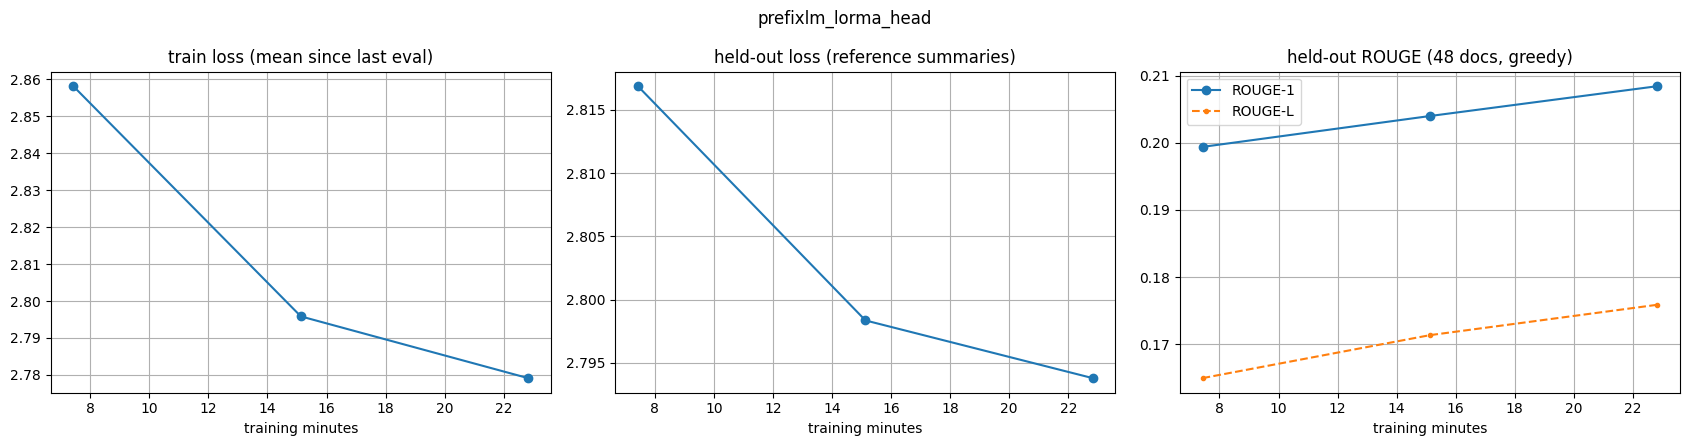

{
 "run": "prefixlm_lorma_head",
 "params_total": 109824768,
 "params_trainable": 294912,
 "params_final": 109529856,
 "model_mb": 417.823486328125,
 "train_minutes": 22.82538555065791,
 "peak_gpu_gb": 2.997923328,
 "best": {
  "score": -2.7937818464343613,
  "metric": "loss",
  "heldout_loss": 2.7937818464343613,
  "rouge1": 0.20844492645478407,
  "rougeL": 0.17586285292519765,
  "epoch": 3,
  "step": 1263
 }
}
{
 "heldout": {
  "main": {
   "bertscore": 0.7642726302146912,
   "rouge1": 0.21815590464083431,
   "rougeL": 0.18174617084009848,
   "words_mean": 413.3833333333333
  }
 }
}
submission zips:
  /content/p6/prefixlm_lorma_head/submission_prefixlm_lorma_head.zip


In [15]:
train_gen_seconds = 0.0
if SAVE_TRAIN_GEN:
    seen = [k for k in TRAIN_KEYS if k in SEEN]
    if TRAIN_GEN_MAX_DOCS and len(seen) > TRAIN_GEN_MAX_DOCS:
        pick = set(np.random.default_rng(SEED).choice(len(seen), TRAIN_GEN_MAX_DOCS, replace=False).tolist())
        seen = [k for i, k in enumerate(seen) if i in pick]
    tg_preds, tg_fb, train_gen_seconds = summaries(model, seen, DECODE)
    json.dump({k: s for (_, k), s in zip(seen, tg_preds)}, open(f"{RUN_DIR}/train_gen.json", "w", encoding="utf-8"),
              ensure_ascii=False)
    print(f"train_gen.json: {len(seen)} training documents summarised ({train_gen_seconds:.0f}s, {tg_fb} empty replaced)")

info = {
    "run": RUN_NAME, "arch": ARCH, "method": METHOD, "doc_select": DOC_SELECT, "p1_repo": P1_REPOS[ARCH],
    "layers": STUDENT_LAYERS if STUDENT else "all", "kept_blocks": model.kept, "n_train_docs": len(TRAIN_KEYS),
    "n_seen_docs": len(SEEN), "heldout_md5": HO_MD5, "n_test_docs": len(TEST_KEYS),
    "config": {k: globals()[k] for k in ("SEED", "HELDOUT_DOCS", "TRAIN_MAX_DOCS", "SRC_LEN", "TGT_LEN", "SEP_TEXT",
                                         "HEAD_FRAC", "EVEN_PIECE", "TFIDF_MAX_FEATURES", "EPOCHS", "MAX_TRAIN_MINUTES",
                                         "EVAL_EVERY_MINUTES", "PATIENCE", "BATCH_SIZE", "GRAD_ACCUM", "GRAD_CKPT", "LR",
                                         "WEIGHT_DECAY", "WARMUP_FRAC", "GRAD_CLIP", "LABEL_SMOOTHING", "SELECT_METRIC",
                                         "EVAL_LOSS_DOCS", "EVAL_GEN_DOCS", "DECODE", "EXTRA_DECODES", "GEN_BATCH",
                                         "MAX_SUMMARY_WORDS", "EMPTY_FALLBACK_WORDS", "ADAPT_TARGETS", "RANK", "ALPHA",
                                         "QLORA_BLOCK", "QLORA_DOUBLE_QUANT", "QLORA_MERGE_FOR_INFERENCE", "LORMA_VARIANT",
                                         "ADALORA_INIT_R", "ADALORA_TARGET_R", "ADALORA_TINIT", "ADALORA_TFINAL",
                                         "ADALORA_DELTA_T", "ADALORA_BETAS", "ADALORA_ORTH", "HOULSBY_AT", "PFEIFFER_AT",
                                         "ADAPTER_DIM", "ADAPTER_TRAIN_NORMS", "PROMPT_LEN", "TEACHER_RUN",
                                         "STUDENT_LAYERS", "KD_TEACHER_PROB", "TRAIN_GEN_MAX_DOCS")},
    "end_marker": END_MARKER, "importance": IMP_INFO, "input_coverage": COVERAGE,
    "params_total": TOTAL_PARAMS, "params_trainable": TRAINABLE_PARAMS, "params_final": FINAL_PARAMS,
    "model_mb": FINAL_MB, "model_mb_trained": TRAINED_MB, "qlora": QUANT_INFO, "adalora_ranks": ADALORA_RANKS or None,
    "train_minutes": train_seconds / 60, "peak_gpu_gb": PEAK_TRAIN_GB, "best": best, "stop": stop,
    "heldout_loss": FINAL_HELDOUT_LOSS, "heldout": HELDOUT, "heldout_reference_stats": REF_STATS,
    "heldout_by_doc_length": BY_LEN, "train_gen_seconds": train_gen_seconds,
    "teacher": teacher_info and {"run": TEACHER_RUN, "arch": teacher_info["arch"], "method": teacher_info["method"],
                                 "params": teacher_info["params_final"], "model_mb": teacher_info["model_mb"],
                                 "heldout": teacher_info["heldout"]["main"], "heldout_md5": teacher_info.get("heldout_md5")},
    "history": history,
}
json.dump(info, open(f"{RUN_DIR}/run_config.json", "w"), indent=1)
if SAVE_WEIGHTS:
    torch.save(model.state_dict(), f"{RUN_DIR}/model.pt")

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
tm = [h["train_minutes"] for h in history]
ax[0].plot(tm, [h["train_loss"] for h in history], marker="o"); ax[0].set_title("train loss (mean since last eval)")
ax[1].plot(tm, [h["heldout_loss"] for h in history], marker="o"); ax[1].set_title("held-out loss (reference summaries)")
ax[2].plot(tm, [h["heldout_rouge1"] for h in history], marker="o", label="ROUGE-1")
ax[2].plot(tm, [h["heldout_rougeL"] for h in history], marker=".", ls="--", label="ROUGE-L")
ax[2].set_title(f"held-out ROUGE ({len(EVAL_GEN_KEYS)} docs, greedy)"); ax[2].legend()
for a in ax: a.set_xlabel("training minutes"); a.grid(True)
fig.suptitle(RUN_NAME); plt.tight_layout(); plt.savefig(f"{RUN_DIR}/curves.png", dpi=130); plt.show()

api.create_repo(P6_REPO, private=True, exist_ok=True)
hb = HELDOUT["main"]
hub_push(lambda: api.upload_folder(folder_path=RUN_DIR, path_in_repo=f"runs/{RUN_NAME}", repo_id=P6_REPO,
                                   commit_message=f"{RUN_NAME} held-out BERTScore {hb['bertscore']} ROUGE-1 {hb['rouge1']:.4f}"),
         f"runs/{RUN_NAME}")
print(json.dumps({k: info[k] for k in ("run", "params_total", "params_trainable", "params_final", "model_mb",
                                       "train_minutes", "peak_gpu_gb", "best")}, indent=1))
print(json.dumps({"heldout": {n: {k: h[k] for k in ("bertscore", "rouge1", "rougeL", "words_mean")} for n, h in HELDOUT.items()}},
                 indent=1))
print("submission zips:", *ZIPS, sep="\n  ")

## All Phase-6 runs so far (from `cs781-p6`, every account)
A table of the saved runs (main decoding) and a mechanical count against the §12.2 requirements (which Phase-1 models
and which §12.2.1 techniques have runs). Counts only — whether two runs are "substantially different" is your judgement.

In [16]:
TECHNIQUE = {"full": "full (reference, not in §12.2.1)", "lora": "lora", "qlora": "qlora", "lorma": "lorma",
             "adalora": "adalora", "houlsby": "houlsby adapters", "pfeiffer": "pfeiffer adapters",
             "prompt": "prompt tuning", "kd": "kd"}
runs = sorted({f.split("/")[1] for f in api.list_repo_files(P6_REPO) if f.startswith("runs/") and f.endswith("/run_config.json")})
rows = []
for r in runs:
    try:
        rows.append(json.load(open(hf_hub_download(P6_REPO, f"runs/{r}/run_config.json", token=HF_TOKEN, force_download=True))))
    except Exception as e:
        print(f"  !! {r}: {e!r}")
print(f"{'run':40s} {'arch':11s} {'method':8s} {'select':10s} {'params':>7s} {'trainable':>10s} {'MB':>6s} {'BERTScore':>9s} "
      f"{'ROUGE-1':>8s} {'ROUGE-L':>8s} {'words':>6s} {'train min':>9s} {'test gen s':>10s} {'held-out':>8s}")
for x in rows:
    h = x["heldout"]["main"]
    print(f"{x['run'][:40]:40s} {x['arch']:11s} {x['method']:8s} {x['doc_select']:10s} {x['params_final']/1e6:6.1f}M "
          f"{x['params_trainable']/1e6:9.3f}M {x['model_mb']:6.0f} {f4(h['bertscore']):>9s} "
          f"{h['rouge1']:8.4f} {h['rougeL']:8.4f} {h['words_mean']:6.0f} {x['train_minutes']:9.1f} {h['test_seconds']:10.0f} "
          f"{x['heldout_md5']:>8s}")
archs = {x["arch"] for x in rows}; techs = {TECHNIQUE[x["method"]] for x in rows}
listed = techs - {"kd", TECHNIQUE["full"]}
print(f"\nPhase-1 models with runs: {sorted(archs)}  (missing: {sorted({'llama', 'bart', 'prefixlm', 'mistral_swa'} - archs)})")
print(f"§12.2.1 techniques with runs (besides KD): {sorted(listed)} ({len(listed)})  LoRMA: {'lorma' in techs}  "
      f"KD: {'kd' in techs};  held-out sets: {len({x['heldout_md5'] for x in rows})} distinct (scores are comparable only "
      f"within the same held-out set)")

run_config.json:   0%|          | 0.00/5.14k [00:00<?, ?B/s]

run_config.json:   0%|          | 0.00/5.13k [00:00<?, ?B/s]

run_config.json:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

run                                      arch        method   select      params  trainable     MB BERTScore  ROUGE-1  ROUGE-L  words train min test gen s held-out
bart_lorma_head                          bart        lorma    head        125.4M     0.442M    479    0.7693   0.2383   0.1909    449      14.2         37 eddb1ace9498
mistral_swa_lorma_head                   mistral_swa lorma    head        100.1M     0.197M    382    0.7622   0.2176   0.1832    424      22.1         68 eddb1ace9498
prefixlm_lorma_head                      prefixlm    lorma    head        109.5M     0.295M    418    0.7643   0.2182   0.1817    413      22.8         75 eddb1ace9498

Phase-1 models with runs: ['bart', 'mistral_swa', 'prefixlm']  (missing: ['llama'])
§12.2.1 techniques with runs (besides KD): ['lorma'] (1)  LoRMA: True  KD: False;  held-out sets: 1 distinct (scores are comparable only within the same held-out set)
